# Assignment 2 — Covariance, VaR, and Copulas

**FinTech 545 — Quantitative Risk Management**

---

Each problem follows the required three-part structure: a **Prediction** made from
the data or a plot of it *before* anything is fitted, the **Fit**, and a
**Reconciliation** that says whether the fit agreed and, where it did not, what had
been missed.

Every definition used here — the PSD condition, Fact 7 for a portfolio variance,
the exponentially weighted estimator and its effective sample size, the two PSD
repairs, the VaR and ES conventions, the copula fitting recipe — is taken from the
Week 02 to Week 05 notes and cited at the point of use, so nothing below rests on a
convention I chose myself. Where a convention *was* mine to choose (how an
empirical quantile is read off a sample, which mean an EW variance removes) the
choice is stated and the alternative is printed alongside it.

### Conventions used throughout

- **VaR and ES are positive for a loss.** $\mathrm{VaR}_\alpha = -F^{-1}(\alpha)$
  on the P&L distribution (Week 04 §4.2) and ES carries the same leading minus
  (Week 05 §5.1). A *negative* VaR therefore means the $\alpha$-quantile of P&L is a
  profit — which happens in Problem 3 and is the point of that problem.
- **Empirical quantiles** follow Week 04 §4.5: sort the $N$ outcomes and take the
  $N\alpha$-th. ES is the mean of those $N\alpha$ worst outcomes. $N\alpha$ is an
  integer for every $N$ and $\alpha$ in this assignment.
- $\alpha = 5\%$ unless a part says otherwise, and the exact $\Phi^{-1}(0.05) =
  -1.6449$ is used rather than $1.65$ so closed-form and simulated numbers can be
  compared to four digits.
- One fixed seed (`common.SEED = 545`) drives every simulation, so every number
  below reproduces exactly.

### Code layout

| file | contents |
|---|---|
| `common.py` | shared helpers: moments, AICc/BIC, VaR/ES, EW variance, Rebonato–Jackel and Higham repairs, PSD Cholesky, plot style |
| `problem1.py` … `problem5.py` | one module per problem, each runnable on its own (`python problem3.py`) and printing every number quoted here |

The notebook imports the modules and calls their functions, so nothing is computed
twice and no number in the prose is typed by hand — every figure quoted in a
markdown cell is printed by the code cell below it. `README.md` lists the commands.

In [1]:
# Standard imports and the shared helper module. Every problem module is written
# to be importable, so the notebook never recomputes anything itself.
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

import common
import problem1, problem2, problem3, problem4, problem5

common.use_style()          # quiet, print-friendly plot style
pd.set_option("display.width", 110)

print("modules loaded")

modules loaded


---

# Problem 1 — Correlations from Mismatched Histories

`problem1.csv`: 250 days of returns for `A`–`D` and an index `IDX` built from them
with weights $0.40/0.30/0.20/0.10$ plus a small tracking error. Blank cells are days
an asset did not trade.

## Predict

### Who trades when

| series | days observed | note |
|---|---|---|
| `A`, `B` | 242 | share a calendar (8 common holidays) |
| `C` | 228 | foreign calendar, 22 holidays scattered through the year |
| `D` | 96 | listed on day 151; blank before that |
| `IDX` | 250 | every day |

Jointly observed days, pair by pair (the code prints the full $5\times5$ table):
`A–B` 242, `A–C`/`B–C` 221, `C–IDX` 228, the `D` pairs 83–96, and **only 81 days on
which all five trade** — a third of the sample, and all of them from the last 100
days, after `D` listed.

### (a) Which estimator can return a non-PSD matrix, and which is guaranteed PSD

**Pairwise can fail; complete-case cannot.**

The complete-case matrix is computed from one rectangular block of 81 standardised
rows $Z$ as $Z'Z/(n-1)$. For any weight vector $w$, $w'Cw = \|Zw\|^2/(n-1) \ge 0$ —
it is the sample variance of the portfolio $w'X$ on those 81 days, and a variance
cannot be negative. That is exactly the PSD definition of Week 02 §2.2.1, and it
holds by construction, whatever the data.

The pairwise matrix has no such $Z$. Each entry is a correlation computed on *its
own* set of days: `A–B` on 242 days, `C–D` on 83, and the `D–IDX` cell on 96. No
single sample produced all ten numbers, so nothing forces them to be mutually
consistent, and Week 03 §3.3 puts it exactly: "a set of mutually inconsistent
correlations is exactly what a negative eigenvalue is."

### (b) What `IDX` being almost a linear combination implies

If `IDX` were *exactly* $0.4A + 0.3B + 0.2C + 0.1D$, the portfolio long one unit of
`IDX` and short the basket would have zero variance, $w'\Sigma w = 0$ for a non-zero
$w$, and $\Sigma$ — hence the correlation matrix — would be singular with a zero
eigenvalue (Week 02 §2.2.1). With a *small* tracking error the smallest eigenvalue
is small but positive.

How small can be bounded without computing a single correlation. On the 81 complete
days the tracking error `IDX − basket` has sd $0.00057$ against `IDX`'s own sd of
$0.01228$ — the index misses its basket by 4.6% of its own volatility. In
standardised units the tracking portfolio is $v = Dw$, and the Rayleigh quotient
bounds the smallest eigenvalue of the true correlation matrix:

$$\lambda_{\min}(C) \;\le\; \frac{v'Cv}{v'v} \;=\; \frac{\mathrm{Var}(\text{TE})}{\sum_i w_i^2\sigma_i^2} \;=\; 0.0014$$

Five eigenvalues sum to 5 and one of them is at most $0.0014$. **The true matrix is
a hair from singular.**

That is what makes this data set so exposed to the failure in (a). A correlation
estimated from $n$ days carries sampling noise of roughly $(1-\rho^2)/\sqrt{n}$, at
most $1/\sqrt{n}$: about $0.10$–$0.11$ for the `D` pairs. The pairwise matrix is ten
such estimates, each wrong by its own independent noise of that order, assembled
into a matrix whose true smallest eigenvalue is $0.0014$. The noise is about **77×**
the room the matrix has before an eigenvalue crosses zero. **I expect the pairwise
matrix to come back with a negative eigenvalue**, and the complete-case matrix to be
PSD but barely — an eigenvalue of order $10^{-3}$.

### (c) Which correlations will be least reliable

Ranked by the days behind them (fewest first): `C–D` (83), `A–D` and `B–D` (93),
`D–IDX` (96), then a step up to the `C` pairs (221–228) and the `A`/`B`/`IDX` pairs
(242). **Everything involving `D` is least reliable, `C–D` worst of all**, with a
worst-case standard error of $0.11$ against $0.064$ for the best-estimated pairs.
There is a second, subtler problem with `D`: its 96 days are *all* the last 100, so
any `D` correlation is also a different *period* from the others, not just a smaller
sample.

In [2]:
# Predict: joint observation counts, the tracking-error bound on the smallest
# eigenvalue of the TRUE correlation matrix, and the pairs ranked by reliability.
d1 = common.load("problem1")
P1 = problem1.part_predict(d1)


Problem 1 -- Predict: who trades when
  Observations per series:
    A     242 days   (first traded day 1)
    B     242 days   (first traded day 1)
    C     228 days   (first traded day 1)
    D      96 days   (first traded day 151)
    IDX   250 days   (first traded day 1)

  Days on which all five trade (complete rows): 81 of 250

  Jointly observed days, pair by pair:
                A        B        C        D      IDX
  A           242      242      221       93      242
  B           242      242      221       93      242
  C           221      221      228       83      228
  D            93       93       83       96       96
  IDX         242      242      228       96      250

  C's holidays (22 days):
    [31, 40, 50, 79, 82, 90, 114, 130, 143, 154, 156]
    [158, 159, 160, 163, 169, 174, 198, 201, 218, 236, 239]
  D's first day: 151; before that every D cell is blank.

  (b) IDX against its own basket, on the complete rows:
      sd of (IDX - basket) = 0.00057  vs  sd

## Fit

### (d) Complete-case and pairwise correlation matrices

| | smallest eigenvalue | all eigenvalues | numpy Cholesky | `chol_psd` |
|---|---|---|---|---|
| complete case (81 rows) | $+0.0015$ | $0.0015,\ 0.548,\ 0.693,\ 0.870,\ 2.886$ | OK | OK |
| pairwise | $\mathbf{-0.0111}$ | $-0.0111,\ 0.471,\ 0.528,\ 0.857,\ 3.154$ | **fails** | **fails** at column 4 (`IDX`), pivot $-0.0164$ |

Both predictions in (b) held: the complete-case matrix is PSD with its smallest
eigenvalue at $0.0015$ (the Rayleigh bound was $0.0014$ — the bound is essentially
tight, because the tracking portfolio *is* the smallest-eigenvalue direction), and
the pairwise matrix is not PSD. Its negative eigenvalue is $-3.5\times10^{-3}$ of the
largest; Week 03 §3.6 draws the line between arithmetic ($-10^{-16}$) and "a
statement that the data are mutually inconsistent" ($-0.05$), and this is on the
data side of it. The Cholesky fails where it should: the `IDX` column is the one
that cannot be reconciled with the four before it.

The matrices themselves differ a great deal. Pairwise `A–C` is $0.431$, complete-case
$0.247$; `B–C` $0.463$ vs $0.317$; `C–IDX` $0.714$ vs $0.565$. Part (i) comes back to
this.

In [3]:
# (d) Both estimators, their eigenvalues, and a Cholesky attempt on each.
D1 = problem1.part_d(d1)


Problem 1(d) -- complete-case vs pairwise correlation
  Complete case (81 rows):
                A        B        C        D      IDX
  A        1.0000   0.3967   0.2466   0.4136   0.8714
  B        0.3967   1.0000   0.3169   0.2361   0.6709
  C        0.2466   0.3169   1.0000   0.1852   0.5648
  D        0.4136   0.2361   0.1852   1.0000   0.5719
  IDX      0.8714   0.6709   0.5648   0.5719   1.0000

  Pairwise (each cell on its own rows):
                A        B        C        D      IDX
  A        1.0000   0.4686   0.4309   0.4384   0.8696
  B        0.4686   1.0000   0.4630   0.2767   0.7329
  C        0.4309   0.4630   1.0000   0.1846   0.7136
  D        0.4384   0.2767   0.1846   1.0000   0.6057
  IDX      0.8696   0.7329   0.7136   0.6057   1.0000

  Eigenvalues (ascending):
    complete case : [1.5058e-03 5.4835e-01 6.9332e-01 8.7044e-01 2.8864e+00]
    pairwise      : [-0.0111  0.4714  0.5284  0.8574  3.1539]
    smallest: complete +0.00151   pairwise -0.01107
    as a f

### (e) Covariance from pairwise correlations and full-history standard deviations

Week 03 §3.4 item 7: correlations from whichever estimator, variances from the full
history of each series, $\Sigma = DCD$. The full-history sds are $0.0165,\ 0.0119,\
0.0183,\ 0.0228,\ 0.0123$ for `A`, `B`, `C`, `D`, `IDX` on 242, 242, 228, 96 and 250
days.

For the tracking portfolio $w = (-0.4, -0.3, -0.2, -0.1, +1)$:

| correlation source | $w'\Sigma w$ |
|---|---|
| **pairwise** | $\mathbf{-1.80\times10^{-6}}$ |
| complete case | $+1.10\times10^{-6}$ |
| realised variance of `IDX − basket` on the 81 complete days | $+0.32\times10^{-6}$ |

**The pairwise covariance assigns a negative variance to a portfolio that exists.**
Its standard deviation would be $\sqrt{-1.8\times10^{-6}}$. In standardised units the
tracking portfolio has cosine $0.997$ with the eigenvector of the negative
eigenvalue: the portfolio the question asks about *is* the direction in which the
matrix fails.

In [4]:
# (e) Sigma = D C D with full-history sds; variance of long IDX / short basket.
E1 = problem1.part_e(P1, D1)


Problem 1(e) -- covariance from pairwise corr + full-history sd
  Full-history standard deviation of each series (its own n):
    A    sd = 0.016502   (n = 242)
    B    sd = 0.011919   (n = 242)
    C    sd = 0.018324   (n = 228)
    D    sd = 0.022829   (n = 96)
    IDX  sd = 0.012281   (n = 250)

  Tracking portfolio w = [-0.4, -0.3, -0.2, -0.1, 1.0]  (long IDX, short basket)
    w' Sigma w  with PAIRWISE correlations      = -1.7994e-06
    w' Sigma w  with COMPLETE-CASE correlations = +1.0975e-06
    realised var of (IDX - basket), complete rows = +3.2221e-07

    The pairwise number is NEGATIVE: sd would be sqrt(-1.799e-06), undefined.
    A portfolio that really exists has been assigned a variance below 0.

    In standardised units the tracking portfolio is v = D w; the cosine
    between v and the eigenvector of the negative eigenvalue is 0.997.
    The portfolio the question asks about IS the direction in which the
    pairwise matrix fails.


### (f) Repairing the pairwise matrix

| method | smallest eigenvalue | $\|C - C_{\text{pw}}\|_F$ | tracking variance |
|---|---|---|---|
| pairwise (input) | $-1.11\times10^{-2}$ | 0 | $-1.80\times10^{-6}$ |
| Rebonato–Jackel (Week 03 §3.6.1) | $-1.9\times10^{-16}$ | $0.0162$ | $+0.681\times10^{-6}$ |
| Higham, $W=I$ (Week 03 §3.6.2) | $-4.9\times10^{-10}$ | $0.0155$ | $+0.679\times10^{-6}$ |

Higham converged in 24 iterations. Both repairs give a positive tracking variance of
the same order as the realised one ($0.68$ vs $0.32$, $\times10^{-6}$; sd $0.00082$
vs $0.00057$), and Higham is the nearer of the two in the Frobenius norm, as it is
designed to be — though only by $0.0007$, and the two repaired matrices differ from
each other by $0.0046$.

One detail worth recording: both repairs **floor** the bad eigenvalue at zero rather
than lifting it above zero, so the repaired matrices are PSD but singular. numpy's
strictly-PD Cholesky still refuses them; the Week 03 §3.2.2 zero-column patch
(`chol_psd`) factors them fine. Week 03 §3.6.3's advice — "check the eigenvalue, not
the norm" — is why the code reports both.

In [5]:
# (f) Rebonato-Jackel and Higham: smallest eigenvalue, Frobenius distance, and the
#     tracking variance under each repaired matrix.
F1 = problem1.part_f(P1, D1)


Problem 1(f) -- repairing the pairwise matrix
  method                   min eig  ||C - C_pw||_F   tracking var
  ---------------------------------------------------------------
  pairwise (input)       -1.11e-02         0.00000     -1.799e-06
  Rebonato-Jackel        -1.86e-16         0.01618     +6.807e-07
  Higham                 -4.90e-10         0.01552     +6.788e-07
  ---------------------------------------------------------------
  Higham converged in 24 iterations (W = I, tol 1e-9).

  Cholesky on the repaired matrices. Both repairs FLOOR the bad eigenvalue
  at zero rather than lifting it above zero, so the result is PSD but
  singular. numpy's strictly-PD routine still refuses it; the Week 03
  s3.2.2 zero-column patch (chol_psd) factors it fine:
    Rebonato-Jackel numpy cholesky : FAILS (Matrix is not positive definite)
                   chol_psd       : OK
    Higham         numpy cholesky : FAILS (Matrix is not positive definite)
                   chol_psd       : OK


## Reconcile

### (g) The negative variance, through the definition of PSD

Week 02 §2.2.1 defines PSD as $w'\Sigma w \ge 0$ for every $w$, and gives the reason
in the same breath: $w'\Sigma w$ *is* the variance of the portfolio $w'X$ (Fact 7
from §2.1.1 in matrix form), and a variance cannot be negative. "Every covariance
matrix is PSD. This is not an assumption we impose, it is forced." A matrix with
$w'\Sigma w < 0$ for some $w$ "assigns a negative variance to a real portfolio … It
is a covariance matrix that cannot have come from any data."

That is precisely what part (e) found, for a portfolio someone could actually hold.
The pairwise $\Sigma$ did not come from any single data set: it came from ten
different ones. The index's pairwise correlations with each stock
($0.87,\,0.73,\,0.71,\,0.61$) say `IDX` tracks the stocks a little *more* closely
than the stock-to-stock correlations and the basket weights can jointly deliver —
so the "unexplained" part of `IDX`, the tracking error, is assigned less than zero
variance. The eigenvalue view says the same thing: $\lambda_{\min} = -0.0111$ along
an eigenvector that is, to cosine $0.997$, the tracking portfolio.

### (h) Which entries Higham moved most, and what it was using

Sorted by the size of the change:

| pair | days | pairwise | Higham | change | $v_iv_j$ |
|---|---|---|---|---|---|
| **`A–IDX`** | **242** | 0.8696 | 0.8625 | **$-0.0070$** | $-0.324$ |
| `C–IDX` | 228 | 0.7136 | 0.7088 | $-0.0048$ | $-0.219$ |
| `B–IDX` | 242 | 0.7329 | 0.7287 | $-0.0042$ | $-0.192$ |
| `D–IDX` | 96 | 0.6057 | 0.6020 | $-0.0037$ | $-0.171$ |
| `A–C` | 221 | 0.4309 | 0.4332 | $+0.0023$ | $+0.105$ |
| `A–B` | 242 | 0.4686 | 0.4706 | $+0.0020$ | $+0.092$ |
| `A–D` | 93 | 0.4384 | 0.4402 | $+0.0018$ | $+0.082$ |
| `B–C` | 221 | 0.4630 | 0.4644 | $+0.0014$ | $+0.062$ |
| **`C–D`** | **83** | 0.1846 | 0.1858 | **$+0.0012$** | $+0.056$ |
| `B–D` | 93 | 0.2767 | 0.2777 | $+0.0011$ | $+0.049$ |

**This is the opposite of my part (c) list.** The entry Higham moved most is
`A–IDX`, built on 242 days — the *best*-estimated entry in the matrix. The entry I
called least reliable, `C–D` on 83 days, moved second-least. Across the ten entries
the correlation between $|\text{change}|$ and $n$ is $+0.49$: the repair moved the
well-estimated entries *more*.

What it is using is in the last column. $v$ is the eigenvector of the negative
eigenvalue, and the Higham change correlates $+1.000$ with $v_iv_j$. With $W = I$,
every entry is equally cheap to move, and the nearest PSD matrix in the plain
Frobenius norm is reached by removing the component along $v$ — a rank-one
correction proportional to $vv'$ — and then resetting the diagonal. The repair was
told nothing about days; it reads the *geometry* of the inconsistency: the `IDX` row
is collectively promising more co-movement than the stock pairs can support, so the
`IDX` row comes down and every stock–stock pair goes up, in proportion to how much
each loads on the offending direction. Rebonato–Jackel does the same thing by a
different route (its column of changes is nearly identical in sign and order).

If one wanted the noisy entries to absorb the correction, Week 03 §3.6.2's weighted
norm is the tool: a diagonal $W$ with larger weights on the better-estimated series
makes their entries expensive to move. Unweighted, Higham answers a different
question from the one part (c) asked.

### (i) The repair against the estimator gap

| | Frobenius norm | largest single entry |
|---|---|---|
| Higham − pairwise | $0.0155$ | $0.0070$ (`A–IDX`) |
| Rebonato–Jackel − pairwise | $0.0162$ | $0.0075$ |
| Higham − Rebonato–Jackel | $0.0046$ | |
| **complete case − pairwise** | $\mathbf{0.424}$ | $\mathbf{0.184}$ (`A–C`) |

The estimator gap is **27× the repair** in norm and 26× in the largest entry. The
choice of estimator moves individual correlations by $0.15$–$0.18$ (`A–C`, `B–C`,
`C–IDX`); the choice of repair moves them by less than $0.01$, and the choice
*between* repairs by less than $0.005$. **For this data the estimator decision is
the one that matters; the repair decision is close to immaterial.**

One qualification, because the tracking portfolio is a special case. For *that*
portfolio the repair changes the variance from $-1.80$ to $+0.68$ ($\times10^{-6}$) —
a bigger move than from Higham to complete case ($+0.68$ to $+1.10$). The repair is
a tiny perturbation of the matrix that happens to be decisive for the one direction
that was broken, and immaterial everywhere else. For any portfolio that is not
nearly degenerate, the $0.18$ disagreement about `A–C` dwarfs anything either
repair did.

Neither estimator is obviously right. The complete case uses 81 rows that are also
the *last* 100 days; its lower stock–stock correlations may be a late-sample regime
or sampling noise (se $\approx 0.1$ at $n = 81$). The pairwise matrix uses three
times the data for most entries and is inconsistent for it. Week 03 §3.4 items 2–3
say: with enough overlap use the complete rows, otherwise go pairwise and repair.
Here the overlap is a third of the sample and in one period, so I would take the
repaired pairwise matrix — and report that the number most sensitive to the choice
is the tracking variance, which neither estimator pins down (the realised value is
$0.32\times10^{-6}$, below both).


Problem 1(g) -- the negative variance, read through the PSD definition
  Week 02 s2.2.1: Sigma is PSD iff w' Sigma w >= 0 for every w, because
  w' Sigma w IS the variance of the portfolio w'X and a variance cannot be
  negative. The pairwise Sigma gives w' Sigma w = -1.799e-06 for the
  tracking portfolio, so it fails the definition at a portfolio that exists.
  The eigenvalue view says the same thing: the smallest eigenvalue is
  -0.0111, and the eigenvector it belongs to points (cosine 1.00) along
  the tracking portfolio. The assembled entries are mutually inconsistent --
  the index is correlated with each stock a little MORE than its basket
  weights and the stock-stock correlations can jointly support.

Problem 1(h) -- where Higham moved the matrix
  Entries sorted by |Higham change|. v_i*v_j is the outer product of the
  negative eigenvector -- the direction a rank-one correction must take:
  pair        n  pairwise   Higham   change   RJ chg  v_i*v_j  complete   cc-pw
  A-IDX

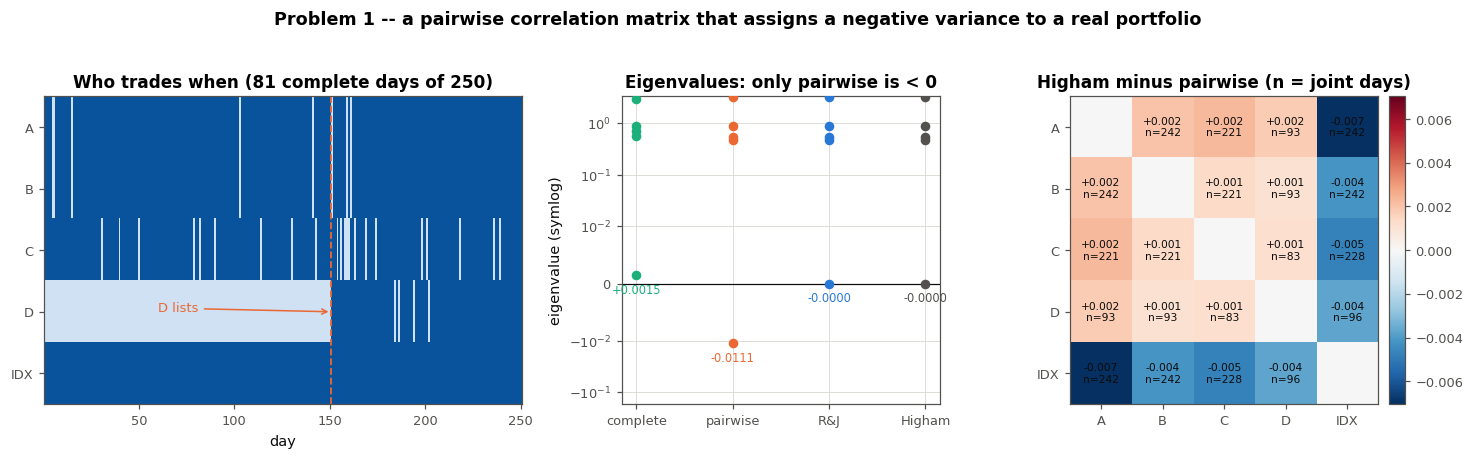

In [6]:
# (g),(h),(i) Negative variance through the PSD definition; where Higham moved the
#     matrix and why; size of the repair against the estimator gap. Then the figure.
T1 = problem1.part_ghi(P1, D1, E1, F1)
problem1.figure(d1, P1, D1, F1, T1)

---

# Problem 2 — A Volatility Estimate After the Regime Changed

`problem2.csv`: 501 daily prices of one stock, so 500 arithmetic returns
$P_t/P_{t-1} - 1$ (Week 04 §4.1.2). The sample mean ($+0.000162$) is removed once,
with equal weights, and everything below treats the demeaned series as having mean
zero. We hold \$1,000,000.

## Predict

### The plot

The left panel below is the demeaned return series. The first $\approx 460$ days
are a steady band with a 20-day rolling sd that stays between $0.007$ and $0.014$. The
last **39 days** are different: the band roughly doubles, the rolling sd runs to
$0.027$, and nine of the ten largest absolute returns in the sample are in that
window. A single-break scan on the variance (the quantitative version of eyeballing
the plot) puts the break after day 461: sd $0.0246$ on the last 39 days against
$0.0102$ before, a ratio of $2.4\times$.

### (a) Ranking the five VaR estimates before computing them

Smallest to largest, I expect **4 ≤ 1 < 5 < 2 < 3**:

1. **Normal, equal-weight sd (1)** — the pooled sd gives the recent regime 39/500 =
   7.8% of the weight, so $\sigma$ will sit near the old regime's $0.010$–$0.012$ and
   the VaR near $1.645\sigma \approx 0.0196$, i.e. \$19–20k.
2. **Normal, EW $\lambda = 0.97$ (2)** and **$\lambda = 0.94$ (3)** — both put most
   of their weight inside the regime (part (b) says 70% and 91%), so $\sigma$ will be
   close to the regime's $0.024$ and both VaRs will be far above (1). The faster
   $\lambda$ sits deeper inside the regime, so **3 > 2**.
3. **Student's $t$ by MLE (4)** — the instinct is "fat tails, so bigger VaR", and at
   5% that instinct is usually wrong. Week 05 §5.1.1: "VaR barely moves across that
   range because the 5% quantile of a unit-variance $t$ is close to the normal's."
   It is in fact slightly *inside* it: a $t_\nu$ scaled to unit variance has 5%
   quantile $t_\nu^{-1}(0.05)\sqrt{(\nu-2)/\nu}$, which is $1.59$ at $\nu = 6$ and
   $1.62$ at $\nu = 10$ against the Normal's $1.645$. The $t$ moves mass from the
   shoulders to the centre and the far tail, and 5% is a shoulder. Fitted to the
   full sample, its variance will be close to the pooled one, so **I expect 4 at or
   just below 1**. This is the ordering I am least sure of.
4. **Historical (5)** — the 25th-worst of 500 days. Ten or so of the 25 worst days
   should come from the 39-day regime, pushing the empirical 5% quantile a little
   past the pooled Normal's, but nowhere near the EW estimates, which are *forecasts
   of the current regime* rather than quantiles of the pooled history.

### (b) Effective sample size, half life, and weight on the regime

Week 03 §3.5.3, $n_{\text{eff}} = (1+\lambda)/(1-\lambda)$ and $h = \ln 0.5/\ln\lambda$:

| $\lambda$ | $n_{\text{eff}}$ | half life (days) | weight on the last 39 days | equal-weight comparison |
|---|---|---|---|---|
| 0.97 | 65.7 | 22.8 | **0.695** | 0.078 |
| 0.94 | 32.3 | 11.2 | **0.910** | 0.078 |

(The infinite-horizon shortcut $1-\lambda^{39}$ gives $0.695$ and $0.910$ to three
decimals — with 500 days of history the normalisation is immaterial.) Equal
weighting gives the regime 8% of the vote; $\lambda = 0.94$ gives it 91%. That is
the whole story of the ranking above.

### (c) Four moments of the full sample

| sd | skewness | excess kurtosis | Jarque–Bera $p$ |
|---|---|---|---|
| $0.01191$ | $-0.156$ ($-1.4$ se) | $\mathbf{+2.166}$ ($\mathbf{+9.9}$ se) | $10^{-21}$ |

Under a single Normal regime excess kurtosis is $0 \pm 0.22$ at $n = 500$. **A
single Normal regime could not produce this sample.** But the plot already says
the sample is not one regime, and a *mixture* of two Normals with different
variances has positive excess kurtosis with no fat tail inside either component. My
prediction is that the $2.17$ is a regime artefact, that each regime on its own will
look close to Normal, and that the fitted $t$'s $\nu$ will be describing the switch
between them rather than the tails of either.


Problem 2 -- Predict: returns, regime, weights, moments
  500 arithmetic returns; sample mean +0.000162 removed.

  Most likely single variance break after day 461: the last 39 days.
    sd of the last 39 days   = 0.02461
    sd of the first 461 days = 0.01017     ratio 2.42x
    20-day rolling sd: median 0.00992 before the break, max 0.02745 inside it

  (b) lambda   n_eff   half-life   weight on last 39 days   equal-weight
      ------------------------------------------------------------------
      0.97      65.7       22.8                 0.695          0.078
      0.94      32.3       11.2                 0.910          0.078
      ------------------------------------------------------------------
      (infinite-horizon shortcut 1 - lambda^K: 0.695 at 0.97, 0.910 at 0.94)
      Equal weighting gives the regime 7.8% of the weight; lambda = 0.94 gives it 91%.

  (c) Full-sample moments (mean removed):
      sd              = 0.011912
      skewness        = -0.1561   (-1.4 se und

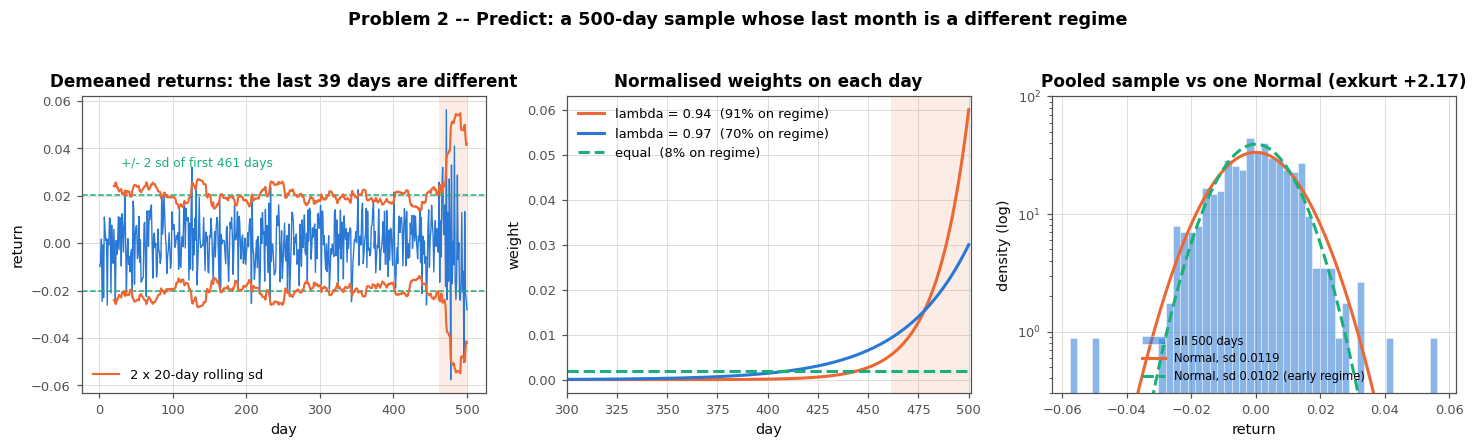

In [7]:
# Predict: returns, the break, n_eff / half life / weight on the regime, moments.
D2 = problem2.prepare()
P2 = problem2.part_predict(D2)
problem2.figure_predict(D2, P2)

## Fit

### (d) The five VaRs on \$1,000,000

| | estimate | $\sigma$ used | VaR (5%) |
|---|---|---|---|
| 1 | Normal, equal-weight sd | $0.01191$ | \$19,594 |
| 2 | Normal, EW sd, $\lambda = 0.97$ | $0.02105$ | \$34,619 |
| 3 | Normal, EW sd, $\lambda = 0.94$ | $0.02353$ | **\$38,707** |
| 4 | Student's $t$ by MLE | $0.01182$ (implied) | **\$18,872** |
| 5 | Historical, 25th worst of 500 | — | \$20,574 |

**Fitted $t$:** $\nu = 8.27$, $\mu = +0.000182$, scale $s = 0.01029$; the implied sd
$s\sqrt{\nu/(\nu-2)} = 0.01182$, within 0.8% of the sample sd. Log-likelihood
$1516.69$ against $1506.13$ for the Normal.

Three convention checks, so that nothing hangs on them: numpy's interpolating
quantile gives a historical VaR of \$20,514 instead of \$20,574 (a \$60 difference);
removing the EW-*weighted* mean instead of the equal-weight mean gives EW sds of
$0.02071$ and $0.02207$ instead of $0.02105$ and $0.02353$; and refitting the $t$ with
its location pinned at zero (the convention the other four estimates use, since
the mean was removed) gives $\nu = 8.36$ and a VaR of \$19,057, still below estimate
1. None of the three moves the ranking or any conclusion below.

In [8]:
# (d) Five VaR estimates in dollars; fitted t parameters; convention checks.
F2 = problem2.part_d(D2, P2)


Problem 2(d) -- five one-day VaR estimates on $1,000,000
  estimate                              sigma used      VaR (5%)
  --------------------------------------------------------------
  1. Normal, equal-weight sd               0.01191       $19,594
  2. Normal, EW sd lambda=0.97             0.02105       $34,619
  3. Normal, EW sd lambda=0.94             0.02353       $38,707
  4. Student t by MLE                      0.01182       $18,872
  5. Historical (25th worst of 500)        0.01191       $20,574
  --------------------------------------------------------------
  Ranked smallest to largest: 4 < 1 < 5 < 2 < 3

  Fitted t: nu = 8.270, mu = +0.000182, scale = 0.010290
            implied sd = scale*sqrt(nu/(nu-2)) = 0.011818  (sample sd 0.011912)
            log-likelihood 1516.69 vs Normal 1506.13

  t refitted with location fixed at 0: nu = 8.361, scale = 0.010306, VaR = $19,057
  (still below estimate 1's $19,594; the ranking does not depend on it)

  Historical VaR with nump

## Reconcile

### (e) The ranking

Realised: **4 < 1 < 5 < 2 < 3**, the predicted order. The two EW estimates are
$1.8$–$2.0\times$ the equal-weight one, as the weight shares in (b) said they would be.

The estimate I was least sure of, the $t$, landed exactly where the shoulder
argument put it: lowest of the five. The fitted $\nu = 8.27$ has a unit-variance 5%
quantile of $1.612$ sd against the Normal's $1.645$, and since the two variances
agree to 0.8%, the whole \$722 gap is shape. The code solves for the crossing: the
fitted $t$'s VaR only exceeds the equal-weight Normal's **below $\alpha = 2.62\%$**.
At 1% the $t$ gives \$29,393 against the Normal's \$27,712, at 0.5% \$34,020 against
\$30,684 — the fat tail is real, it just lives further out than 5%.

The historical number sits above the Normal because **10 of the 25 worst days come
from the 39-day regime** — 40% of the tail from 8% of the sample. It still lands
\$14k below the EW estimates, because an unweighted quantile of the pooled history
is a statement about the last two years, not about tomorrow.

### (f) Inside each regime

| regime | days | sd | skew | excess kurtosis | se(exkurt) |
|---|---|---|---|---|---|
| recent (last 39) | 39 | $\mathbf{0.0246}$ | $+0.20$ | $-0.05$ | $0.78$ |
| earlier (first 461) | 461 | $\mathbf{0.0102}$ | $-0.22$ | $-0.20$ | $0.23$ |

**Neither regime is fat-tailed.** Both excess kurtoses are within one standard error
of zero. A two-component scale mixture of Normals has

$$\text{excess kurtosis} = 3\,\frac{p\sigma_1^4 + (1-p)\sigma_2^4}{\left(p\sigma_1^2 + (1-p)\sigma_2^2\right)^2} - 3$$

and with $p = 39/500$, $\sigma_1 = 0.0246$, $\sigma_2 = 0.0102$ this gives $+2.68$
against the observed $+2.17$ (and an implied sd of $0.01194$ against $0.01191$). Two
Normals with different variances account for all of the pooled kurtosis — slightly
more than all, because the break is not a clean step and a few days near it belong
to neither sd.

So **the fitted $t$ is describing the pooled, unconditional mixture**: a distribution
that no single day was drawn from. Its $\nu = 8.3$ is not a measure of how fat the
tails are on any given day; it is a measure of how different the two regimes are and
how much of the sample each occupies. The question "what is the VaR of \$1M held
*tomorrow*?" is a question about the current regime, whose sd is $0.0246$, and a
Normal with that sd — which is essentially what the EW estimates are — describes
tomorrow far better than the $t$ fitted to two years does. The $t$ is the best
fitting distribution by likelihood and the worst of the five VaR estimates for the
purpose, and both statements are true at once.

### (g) Is the EW gap bigger than the EW noise?

Week 03 §3.5.3: $\text{se}(\hat\sigma) \approx \sigma/\sqrt{2\,n_{\text{eff}}}$.

| $\lambda$ | $\hat\sigma$ | $n_{\text{eff}}$ | se$(\hat\sigma)$ | in VaR terms |
|---|---|---|---|---|
| 0.97 | $0.02105$ | 65.7 | $0.00184$ (8.7%) | $\pm$\$3,021 |
| 0.94 | $0.02353$ | 32.3 | $0.00293$ (12.4%) | $\pm$\$4,813 |

The gap between the two EW VaRs is **\$4,088** — $0.85$ standard errors of the
$\lambda = 0.94$ estimate alone, and $0.72$ standard errors of the difference. **No,
the gap is not larger than the noise.** The two $\lambda$s do not disagree about
today's volatility; they disagree about how much of the last month to believe, and
at $n_{\text{eff}} = 32$ the faster one cannot tell a $2.3\%$ sd from a $2.6\%$ one.
Reporting either to the dollar overstates what is known.

**Opinion, labelled as such.** Week 03 §3.5.4: "A risk limit that triggers trading
wants responsiveness. A capital calculation wants stability." For a **trading limit**
I would use $\lambda = 0.94$: a limit exists to react, and an 11-day half life reacts
inside two weeks of a regime change, at the price of occasional false alarms. For a
**capital number** I would use $\lambda = 0.97$ or slower: capital should not swing
by 20% on a month of data that carries a 12% standard error, and a 23-day half life
still absorbs a persistent shift within a quarter. I would *not* use the
equal-weight or $t$ numbers for either purpose here — stable is not the same as
blind, and \$19k is a description of last year.


Problem 2(e) -- the ranking, and the estimate that moved
  5% quantile of a UNIT-VARIANCE t with nu = 8.27: 1.612 sd, vs 1.645 for the Normal.
  The t's implied sd (0.01182) is within 0.8% of the sample sd (0.01191),
  so the whole gap comes from the SHAPE: a t puts more mass in the centre
  and in the far tail than a Normal of the same variance, and takes it
  from the shoulders -- which is where the 5% quantile sits.
  The fitted t's VaR exceeds the equal-weight Normal's only below alpha = 2.62%.
    alpha  5.0%: Normal    $19,594   t    $18,872   historical    $20,574
    alpha  2.5%: Normal    $23,347   t    $23,413   historical    $23,730
    alpha  1.0%: Normal    $27,712   t    $29,393   historical    $26,051
    alpha  0.5%: Normal    $30,684   t    $34,020   historical    $28,111

  Historical: 10 of the 25 worst days fall inside the last 39-day regime
  (40% of the tail from 8% of the sample), which is what lifts it above the
  equal-weight Normal without getting anywhere ne

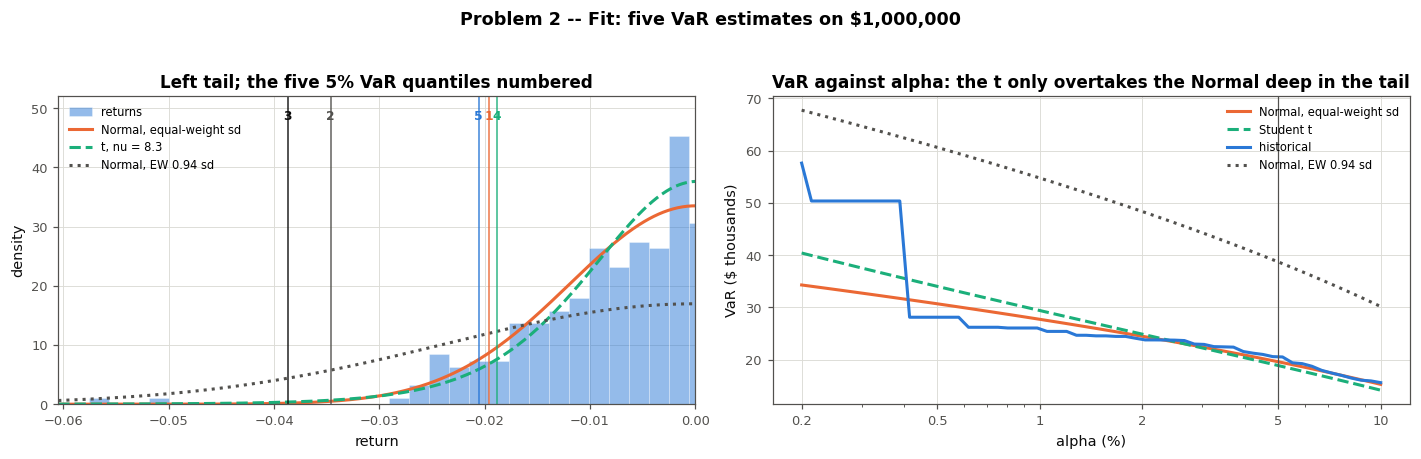

In [9]:
# (e),(f),(g) Reconcile: the ranking and the t's crossing point; within-regime sds
#     and the mixture kurtosis; EW standard errors against the EW gap. Then the
#     fit figure.
E2 = problem2.part_e(D2, P2, F2)
R2 = problem2.part_f(D2, P2)
G2 = problem2.part_g(F2)
problem2.figure_fit(D2, P2, F2)

---

# Problem 3 — When Diversification Raises VaR

`problem3.csv`: 10,000 simulated one-year return scenarios for bonds `A` and `B`,
each bought at 90 and paying 100 unless it defaults. \$2,000,000 to invest: all in
`A`, or \$1,000,000 in each. With arithmetic returns a position's P&L is holding
$\times$ return and a portfolio's P&L is the sum (Week 04 §4.1.2).

## Predict

### The P&L plots

The figure below (log count scale, so the default lump is visible next to the
coupon spike) is two-lump in both panels. Concentrated: a spike of about 9,600
scenarios around +\$220k and a lump of about 400 around −\$1.1M, with nothing in
between. Diversified: the spike narrows and moves to +\$220k, a *second* lump of
about 770 scenarios appears around −\$450k (one bond defaulted, the other paid its
coupon), and a sliver of 17 sits near −\$1.1M (both defaulted).

### (a) Moments, and what they say about a Normal VaR

| bond | mean | sd | skewness | excess kurtosis |
|---|---|---|---|---|
| `A` | $+8.37\%$ | $13.60\%$ | $-4.82$ | $22.1$ |
| `B` | $+8.50\%$ | $13.21\%$ | $-4.92$ | $23.1$ |

The no-default return is $100/90 - 1 = +11.1\%$ (the data scatter around it with
sd $1.1\%$), and the default returns run from $-83\%$ to $-22\%$ — recoveries of 15
to 70 on the 90 paid. A skew of $-4.8$ and excess kurtosis of $22$ from a two-lump
distribution: a spike near $+11\%$, a lump near $-80\%$, and an empty middle.

A Normal with this mean and sd puts its 5% quantile at $\mu - 1.645\sigma = -14\%$.
Returns anywhere between $-30\%$ and $-5\%$ occur in **9 of 10,000 scenarios**. The
Normal VaR will describe a region of the distribution that is essentially empty,
and it will be wrong in *both* directions depending on $\alpha$: too large at 5% for
a single bond (whose true 5% quantile is a coupon year, a profit) and far too small
at 1% (where the truth is a default losing $\sim$65% of the position). The moments
tell us a Normal VaR is not a rough approximation here; it is unrelated to the
distribution.

### (b) Counts, and a prediction from them

| event | scenarios | frequency |
|---|---|---|
| `A` loses more than 20% | 406 | 4.06% |
| `B` loses more than 20% | 393 | 3.93% |
| at least one of the two | **782** | **7.82%** |
| both | 17 | 0.17% (independence predicts 16.0) |

The two bonds are independent (return correlation $+0.002$, double defaults as
predicted by the product of the marginals). One `B` scenario sits at $-19.6\%$ — a
high-recovery default that the "more than 20%" cut leaves out; it changes none of
the arithmetic below.

Five percent of 10,000 is the **500 worst scenarios**. Concentrated in `A`, only 406
of those are defaults — the 500th-worst scenario is a coupon year, so the 5% VaR
will be a **profit** of roughly 2 × \$1M × 8% ≈ \$170k (negative VaR).
Diversified, 782 scenarios hold a default, so the 500th-worst *is* a default: one
bond loses about \$1M × 56% ≈ \$565k while the other earns ≈ \$110k,
a net loss of roughly **\$450k**. **The diversified choice has the LARGER VaR, by
about \$600k.**

ES averages the 500 worst. Concentrated: ≈ 406 defaults at ≈ \$1.13M each plus
94 coupon years, so roughly \$0.88M. Diversified: ≈ 483 single defaults at
≈ \$450k net plus 17 double defaults at ≈ \$1.13M, so roughly \$0.48M — both
figures biased low because the tail holds the *low-recovery* defaults, not average
ones. **The diversified choice has the SMALLER ES, by about half.**

This is the Week 04 §4.3.2 counterexample with real recoveries: splitting the money
moves the default event from 4% (below the 5% line, invisible to VaR) to 7.8% (above
it, counted in full), while halving what a single default costs.


Problem 3 -- Predict: moments and default counts
  (a) Four moments of each bond's one-year RETURN:
  bond               mean          sd     skew   exkurt
  A               8.3709%    13.5988%   -4.823   22.094
  B               8.5011%    13.2102%   -4.916   23.087

      Return if no default = 100/90 - 1 = +11.1111% (the data scatter around it:
      non-default A returns run +0.069 to +0.152, sd 0.0111).
      Default returns run -0.830 to -0.219: recovery of 15-70 on the 90 paid.
      Skew of -4.8 and excess kurtosis of 22 from a two-lump distribution:
      a spike near +11% and a lump near -80%, with nothing in between. A Normal
      with this mean and sd puts its 5% quantile at mu - 1.645 sd = -0.140,
      a 14% loss. Returns anywhere between -30% and -5% occur in 9 of
      10000 scenarios: the Normal VaR describes a region of the distribution
      that is essentially empty.

  (b) Scenarios losing more than 20%:
      A alone            :   406   (4.06%)
      B alone   

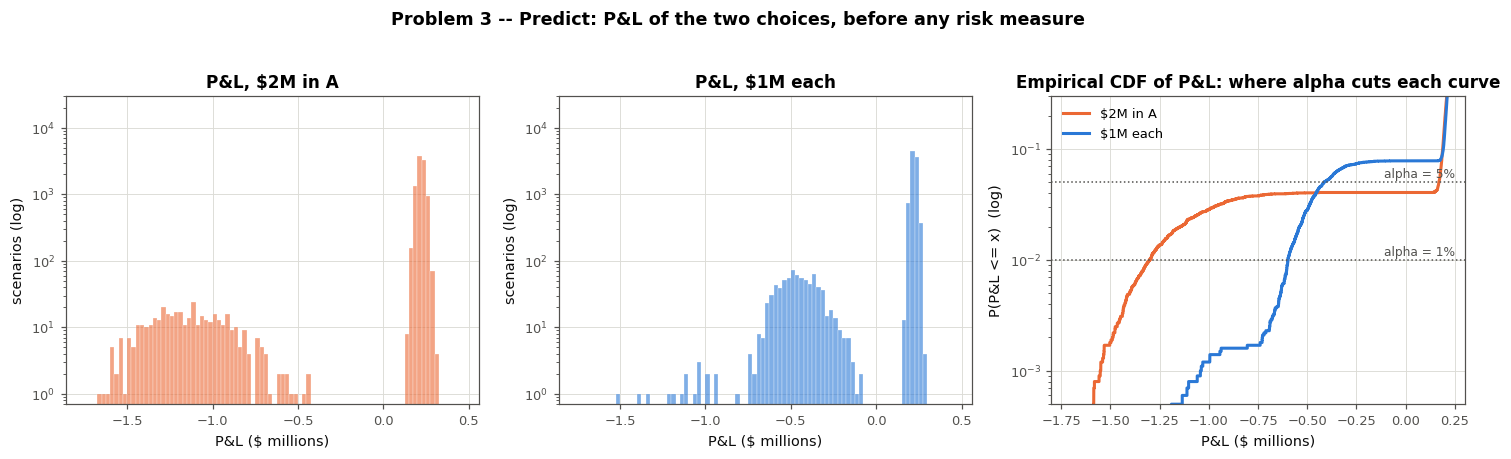

In [10]:
# Predict: P&L plots, four moments of each bond, default counts, and the
# count-based prediction for VaR and ES.
D3 = problem3.prepare()
P3 = problem3.part_predict(D3)
problem3.figure(D3, name="problem3_predict")

## Fit

### (c) Historical VaR and ES at 5%

| position | VaR | ES |
|---|---|---|
| \$1M in `A` | **$-$\$84,531** (a profit) | \$443,628 |
| \$1M in `B` | **$-$\$86,011** (a profit) | \$419,587 |
| \$2M in `A` | **$-$\$169,061** (a profit) | \$887,257 |
| \$1M in each | **\$414,767** | \$541,997 |

### (d) Normal VaR from the sample mean and sd of each P&L

$\mathrm{VaR} = -(\mu + \sigma\,\Phi^{-1}(0.05))$, the absolute P&L quantile of Week 04
§4.2.1 — the mean is kept because the question asks for it.

| position | mean P&L | sd P&L | Normal VaR | historical VaR |
|---|---|---|---|---|
| \$1M in `A` | \$83,709 | \$135,988 | \$139,971 | $-$\$84,531 |
| \$1M in `B` | \$85,011 | \$132,102 | \$132,277 | $-$\$86,011 |
| \$2M in `A` | \$167,418 | \$271,975 | **\$279,941** | $-$\$169,061 |
| \$1M in each | \$168,721 | \$189,796 | **\$143,466** | \$414,767 |

The sd ratio diversified/concentrated is $0.698$, against the $1/\sqrt2 = 0.707$ of
two independent equal positions.

### (e) Historical VaR and ES at 1%

| position | VaR | ES |
|---|---|---|
| \$1M in `A` | \$650,545 | \$709,548 |
| \$1M in `B` | \$641,248 | \$700,805 |
| \$2M in `A` | **\$1,301,090** | \$1,419,096 |
| \$1M in each | **\$598,237** | \$716,408 |

In [11]:
# (c) historical VaR/ES at 5%; (d) Normal VaR from mean and sd; (e) at 1%.
R5_3 = problem3.part_c(D3)
N3 = problem3.part_d(D3)
R1_3 = problem3.part_e(D3)


Problem 3(c) -- historical VaR and ES at alpha = 5%
  position               VaR            ES  VaR/ES ratio
  ------------------------------------------------------
  $1M in A          -$84,531      $443,628         -0.19
  $1M in B          -$86,011      $419,587         -0.20
  $2M in A         -$169,061      $887,257         -0.19
  $1M each          $414,767      $541,997          0.77
  ------------------------------------------------------
  A negative VaR is a PROFIT at the 5% quantile: the 500th-worst scenario
  for $2M in A is still a coupon-paying year.

Problem 3(d) -- Normal VaR from the sample mean and sd of each P&L
  position         mean P&L       sd P&L  Normal VaR 5%   hist VaR 5%
  -------------------------------------------------------------------
  $1M in A          $83,709     $135,988       $139,971      -$84,531
  $1M in B          $85,011     $132,102       $132,277      -$86,011
  $2M in A         $167,418     $271,975       $279,941     -$169,061
  $1M each

## Reconcile

Both predictions held, and the count-based magnitudes were close: VaR a −\$169k
profit against +\$415k loss (predicted −\$170k and ≈ \$450k); ES \$887k against
\$542k (predicted ≈ \$880k and ≈ \$480k, the diversified figure low by 12% for
the reason flagged — the 483 single defaults in the tail are the low-recovery ones).

### (f) Subadditivity at 5%

| | $q(A) + q(B)$ | $q(A+B)$ | subadditive? |
|---|---|---|---|
| **VaR** | −\$84,531 − \$86,011 = −\$170,542 | \$414,767 | **No — violated by \$585k** |
| **ES** | \$443,628 + \$419,587 = \$863,216 | \$541,997 | Yes, with \$321k to spare |

The mechanism is the one Week 04 §4.3.2 describes, and the counts in (b) are the
whole of it. Each bond alone defaults in 4.06% / 3.93% of scenarios — below 5% — so
its 5% quantile is a coupon year and its VaR is a profit. Together, at least one
defaults in 7.82% of scenarios — above 5% — so the combined 5% quantile is a default.
Splitting the money moved 3.76% of probability mass across the 5% line, and "a
measure that reads a single quantile is blind to everything on the far side of it,
and diversification moves things across."

ES cannot be surprised this way because it averages the entire tail: every default
in `A` and every default in `B` was already inside the two single-bond ES figures.
Combining the positions *lowers* ES because a single default now costs \$1M $\times$
loss instead of \$2M $\times$ loss, and the 17 double defaults (0.17%) are far too few
to offset that. Coherence (Week 05 §5.1.2, Table 5.1) is the one-row difference
between the two measures, and this is the row.

### (g) What the Normal VaR gets right, and why it is still wrong

| measure | \$2M in `A` | \$1M in each | favours |
|---|---|---|---|
| Normal VaR 5% | \$279,941 | \$143,466 | diversify, by \$136k |
| historical VaR 5% | $-$\$169,061 | \$414,767 | **concentrate**, by \$584k |
| historical ES 5% | \$887,257 | \$541,997 | diversify, by \$345k |

The Normal favours diversifying, and ES agrees that diversifying is the better
choice. But the Normal is right **for the wrong reason**, and its numbers are wrong
for every position. Its only mechanism is that the sd of two independent equal
positions falls by $1/\sqrt2$ and a Normal VaR is $1.645\sigma$. The real benefit of
diversifying here is that one default costs half as much (that is what ES measures);
the real cost — which the 5% VaR reports — is that defaults become twice as frequent
in the portfolio. A Normal has no defaults in it. It describes a bell curve centred
on +\$170k that no scenario follows, says the concentrated position risks losing
\$280k when it actually risks losing \$1.3M or nothing, and says diversifying saves
\$136k when at this $\alpha$ it moves the VaR from a profit to a \$415k loss.

### (h) Why 1% flips the VaR result

| | VaR 5% | VaR 1% | ES 5% | ES 1% |
|---|---|---|---|---|
| \$2M in `A` | $-$\$169,061 | **\$1,301,090** | \$887,257 | \$1,419,096 |
| \$1M in each | \$414,767 | **\$598,237** | \$541,997 | \$716,408 |

At 1% the threshold sits below every single-default probability. $P(A\ \text{defaults})
= 4.06\% > 1\%$, so the concentrated VaR now sees a \$2M default. $P(\text{at least
one}) = 7.82\% > 1\%$, so the diversified VaR still sees one \$1M default — but
$P(\text{both}) = 0.17\% < 1\%$, so it never sees the double default. The diversified
VaR is less than half the concentrated one and VaR is subadditive again.

**VaR fails when $\alpha$ falls between the probability of the bad event in one
position and in the combination** — here between 4.1% and 7.8%. Five percent is
inside that window; one percent is not. Whether VaR "works" is therefore not a
property of the portfolio or of the measure alone: it depends on where $\alpha$ lands
relative to the lumps of probability in the loss distribution — which is exactly the
sort of thing a risk measure should not depend on. The failure shows up when the
loss distribution has mass concentrated at a few points (defaults, barriers,
jumps) and a decision moves one of those points across the threshold. ES has no
such window, and its ranking of the two choices is the same at 5% and at 1%.


Problem 3(f) -- subadditivity at 5%
  VaR: q(A) + q(B) = -$84,531 + -$86,011 = -$170,542   vs   q(A+B) = $414,767
       subadditive (q(A)+q(B) >= q(A+B))?  NO -- VIOLATED
  ES : q(A) + q(B) = $443,628 + $419,587 = $863,216   vs   q(A+B) = $541,997
       subadditive?  YES

  Mechanism (Week 04 s4.3.2). Each bond defaults in 4.06% / 3.93% of
  scenarios, both below 5%, so each bond's 5% quantile is a coupon year and
  its VaR is a profit. Together, at least one defaults in 7.82% of
  scenarios, above 5%, so the combined 5% quantile is a default. Splitting
  the money moved 3.76% of probability mass across the 5% line, and a
  measure that reads one quantile sees nothing on the far side of it.
  ES averages the whole tail: it already counted every default in A and in B
  separately, so combining cannot surprise it. It falls because a single
  default now costs $1M x loss instead of $2M x loss, and the 17 double
  defaults (0.17%) are too few to offset that.

Problem 3(g) -- what the No

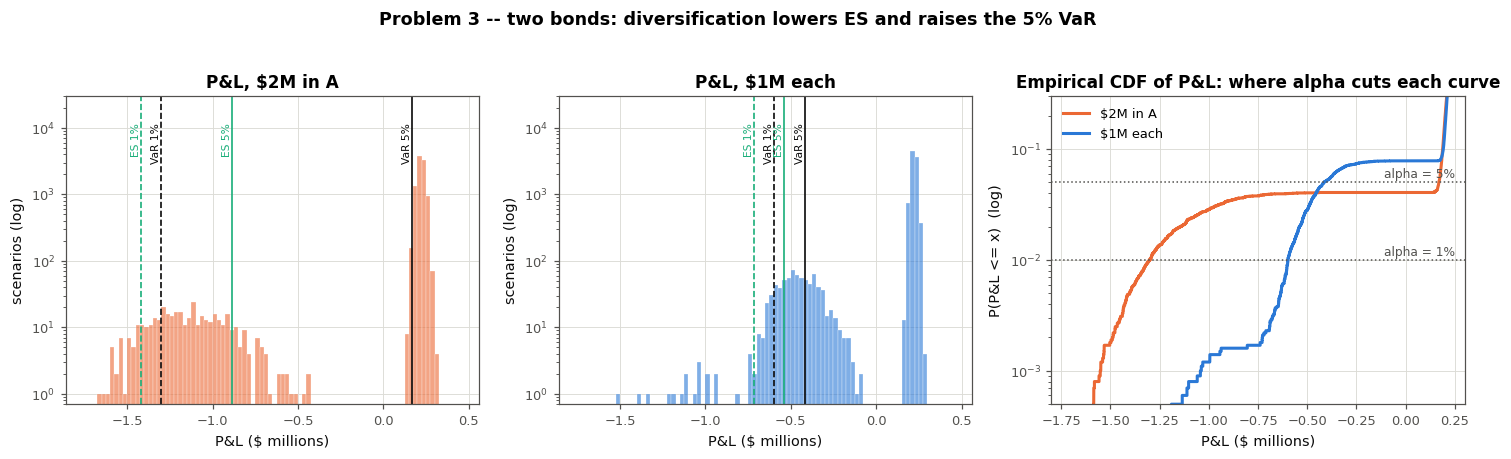

In [12]:
# (f) subadditivity at 5%; (g) the Normal's verdict; (h) the flip at 1%. Then the
#     P&L figure with the VaR / ES levels drawn in.
S3 = problem3.part_f(D3, P3, R5_3)
problem3.part_g(R5_3, N3)
problem3.part_h(D3, P3, R5_3, R1_3)
problem3.figure(D3, R5_3, R1_3)

---

# Problem 4 — Gaussian or $t$ Copula

`problem4.csv`: 1,000 days of returns for `X1`–`X3`; \$1,000,000 in each.

## Predict

### (a) Moments, and the one day that carries them

| series | mean | sd | skewness | excess kurtosis |
|---|---|---|---|---|
| `X1` | $+0.026\%$ | $1.19\%$ | $-0.03$ | $-0.12$ |
| `X2` | $-0.025\%$ | $1.62\%$ | $-0.62$ | $\mathbf{7.12}$ |
| `X3` | $+0.089\%$ | $1.00\%$ | $+0.07$ | $2.87$ |

(se under normality: $0.077$ for skew, $0.155$ for excess kurtosis.)

From the moments alone: **`X1` is Normal** (excess kurtosis $-0.8$ se from zero,
skew nil); **`X2` and `X3` want a Student's $t$** (symmetric to within noise, excess
kurtosis $46$ and $19$ se above zero). The number that looks out of place is `X2`'s
$7.12$ — three times `X3`'s on a series that otherwise looks similar.

Dropping the single most extreme observation of each series:

| series | day | value | z-score | excess kurtosis, all | without that day |
|---|---|---|---|---|---|
| `X1` | 951 | $-0.040$ | $-3.4$ | $-0.12$ | $-0.19$ |
| `X2` | 951 | $-0.143$ | $\mathbf{-8.8}$ | $7.12$ | $\mathbf{1.73}$ |
| `X3` | 951 | $-0.061$ | $-6.2$ | $2.87$ | $1.73$ |

**One day carries 5.4 of `X2`'s 7.1.** Without it `X2` and `X3` both sit at $+1.73$ —
still 11 se from Normal, so both still want a $t$, but a $t$ with $\nu$ in the 5–7
range rather than the $\nu \approx 4$ that $7.1$ would suggest. And the same day,
**951, is the most extreme observation of all three series at once**: an $8.8$-sigma
day in `X2`, $6.2$ in `X3`, $3.4$ in `X1`. That is a joint tail event, and it is the
first hint that the question here is about the copula, not just the margins.

### (b) Ranks, pair plots, and the joint 2.5% corners

Ranks are scaled as $\text{rank}/(n+1)$ so they stay strictly inside $(0,1)$. The
three rank scatter plots below are the picture of a copula with the margins stripped
out: each is a diffuse diagonal cloud, denser toward both corners than toward the
off-diagonal corners, with the orange point (day 951) in the bottom-left of all
three.

"Worst 2.5%" is the 25 lowest ranks of each series. Under **independence** a pair
would put $1000 \times 0.025^2 = 0.625$ days in a corner. But independence is the
wrong benchmark for the question asked, which is whether the tails are more
connected than the *middle*. The middle is summarised by the rank correlation, so
the right comparison is with a **Gaussian copula at the pair's own correlation** —
the copula with exactly that correlation and no tail dependence. $\rho$ is taken
from Kendall's $\tau$ via $\rho = \sin(\pi\tau/2)$ (Week 05 §5.5.3.1), which is also
what the fit will use.

| pair | $\tau$ | $\rho$ | both worst 2.5% | both best 2.5% | independence | Gaussian | $t_8$ | $t_4$ |
|---|---|---|---|---|---|---|---|---|
| `X1–X2` | 0.396 | 0.583 | 6 | 8 | 0.63 | 5.93 | 7.59 | 9.05 |
| `X1–X3` | 0.335 | 0.503 | 7 | 12 | 0.63 | 4.66 | 6.32 | 7.80 |
| `X2–X3` | 0.307 | 0.464 | 6 | 9 | 0.63 | 4.14 | 5.78 | 7.26 |
| **all six corners** | | | **19** | **29** | 3.75 | **29.5** | 39.4 | 48.2 |

Against independence the corners are crowded 13-fold — but most of that is just
correlation: the Gaussian copula, with no tail dependence at all, already expects
29.5 of the 48 corner days. The excess over the Gaussian is **$+19$ days, about 3.4
Poisson standard deviations**. The corners are more connected than the correlation
of the middle can explain, which is what tail dependence looks like, and the
upper corners (29) are as crowded as the lower (19) are, consistent with the
symmetric tails of a $t$ copula.

A $t$ copula at these correlations reproduces the 48 corner days at **$\nu \approx 4$**.
**Prediction: the $t$ copula wins, with a single-digit $\nu$ near 4.** I expect the
margin to be clear rather than a near tie, because 3.4 Poisson sd on the corners
alone is already a lot of evidence and the likelihood sees the whole sample.


Problem 4(a) -- moments of each series
  Under H0: Normal, se(skew) = 0.077 and se(exkurt) = 0.155 at n = 1000.
  series             mean          sd     skew   exkurt
  X1              0.0257%     1.1894%   -0.034   -0.117
  X2             -0.0252%     1.6168%   -0.615    7.125
  X3              0.0890%     1.0019%    0.074    2.874

  Drop the single most extreme day of each series and recompute:
  series     day     value  z-score  exkurt all  exkurt w/o  skew w/o
  X1         951   -0.0400    -3.38      -0.117      -0.188    -0.005
  X2         951   -0.1429    -8.82       7.125       1.725     0.056
  X3         951   -0.0612    -6.20       2.874       1.731     0.313

  The same day (951, 0-indexed) is the most extreme observation of ALL
  THREE series: X1 -0.0400, X2 -0.1429, X3 -0.0612. That is a joint
  tail event, and it is the first hint about the copula, not just the margins.

  X2's excess kurtosis of 7.1 is the number that looks out of place: one day
  carries 5.4 of it.

  A t copula at these correlations reproduces the 48 corner days at nu ~ 4.1.
  Prediction: the t copula wins, with a single-digit nu.


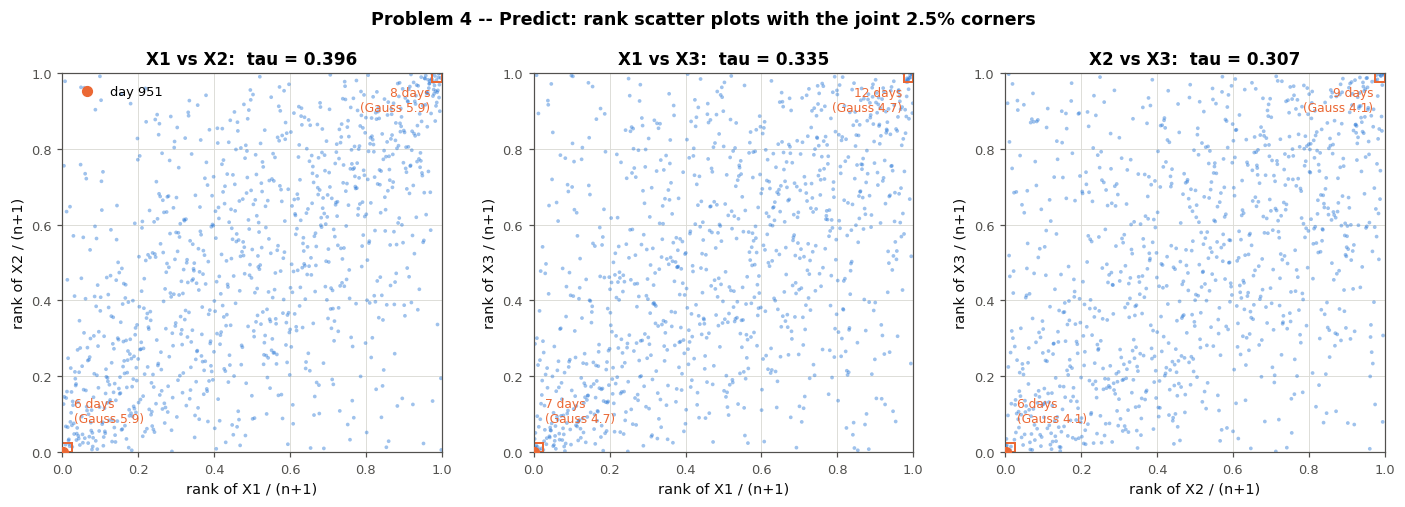

In [13]:
# Predict: moments with the leave-one-out check, rank scatter plots, and the joint
# tail counts against independence, a Gaussian copula and two t copulas.
d4 = common.load("problem4")
A4 = problem4.part_a(d4)
B4 = problem4.part_b(d4)
problem4.figure_predict(d4, A4, B4)

## Fit

### (c) Normal or $t$ for each margin, by AICc

$k = 2$ for the Normal, $k = 3$ for the $t$ (Week 02 §5.3), $n = 1000$. $\nu$ is
bounded above at 100 (Week 05 §5.5.3.2: past there a $t$ and a Normal are
indistinguishable).

| series | $\ell$ Normal | $\ell$ $t$ | $\hat\nu$ | AICc Normal | AICc $t$ | $\Delta$AICc | choice |
|---|---|---|---|---|---|---|---|
| `X1` | 3013.27 | 3012.92 | $\ge 100$ | $-6022.54$ | $-6019.81$ | $+2.73$ | **Normal** |
| `X2` | 2706.25 | 2762.10 | **5.27** | $-5408.49$ | $-5518.18$ | $-109.69$ | **$t$** |
| `X3` | 3184.85 | 3217.02 | **6.09** | $-6365.69$ | $-6428.02$ | $-62.32$ | **$t$** |

Exactly as the moments said. For `X1` the $t$'s $\nu$ runs to its bound and its
likelihood matches the Normal's, so AICc charges it 2.7 for a parameter that bought
nothing. The fitted $t$ margins: `X2` $\mu = -0.000176$, $s = 0.01254$, $\nu = 5.27$
(implied sd $0.01592$); `X3` $\mu = +0.000746$, $s = 0.00818$, $\nu = 6.09$ (implied
sd $0.00998$). Both $\nu$s are in the range the leave-one-out kurtosis of $1.73$
pointed to, not the range the raw $7.1$ did.

In [14]:
# (c) Normal vs t for each margin, chosen by AICc.
M4 = problem4.part_c(d4)


Problem 4(c) -- Normal vs Student t for each margin, by AICc
  series    ll Normal      ll t      nu     AICc N     AICc t   dAICc   choice
  --------------------------------------------------------------------------------


  X1          3013.27   3012.92   >=100   -6022.54   -6019.81   +2.73   Normal
  X2          2706.25   2762.10    5.27   -5408.49   -5518.18 -109.69   t
  X3          3184.85   3217.02    6.09   -6365.69   -6428.02  -62.32   t
  --------------------------------------------------------------------------------
  k = 2 for the Normal (mu, sigma), k = 3 for the t (mu, scale, nu). For X1 the t's
  nu runs to its upper bound and its likelihood equals the Normal's, so AICc
  charges it for a parameter that bought nothing. Fitted t margins:
    X1: mu = +0.000260, scale = 0.011779, nu = 100.00, implied sd = 0.011898
    X2: mu = -0.000176, scale = 0.012544, nu = 5.27, implied sd = 0.015923
    X3: mu = +0.000746, scale = 0.008181, nu = 6.09, implied sd = 0.009981


### (d) Uniforms, $R$ from Kendall's $\tau$, and the two copulas

Following Week 05 §5.6.1: each series is transformed to $U_i = F_i(x_i)$ through its
*fitted* margin (KS tests against the uniform give $p = 0.91, 0.96, 0.83$), $R =
\sin(\pi\tau/2)$ is estimated once and handed to both copulas, and $\nu$ is profiled
with $R$ held fixed on $\theta = 1/\nu \in [0.01, 0.49]$ (200-point grid, then
refined between the neighbours). The copula log-likelihood is computed as
$\ln f_{R,\nu}(y) - \sum_i \ln f_\nu(y_i)$ — the log of the ratio, never the ratio
(§5.6.2). With the margins frozen, $k_{\text{Gauss}} = 0$ and $k_t = 1$ (§5.6.5).

$$R = \begin{pmatrix} 1 & 0.583 & 0.503 \\ 0.583 & 1 & 0.464 \\ 0.503 & 0.464 & 1 \end{pmatrix}, \qquad \text{eigenvalues } 0.413,\ 0.552,\ 2.035 \text{ — PSD, no repair.}$$

| copula | $\ell$ | $k$ | $\hat\nu$ | AICc | BIC |
|---|---|---|---|---|---|
| Gaussian | 350.44 | 0 | — | $-700.88$ | $-700.88$ |
| **$t$** | **452.00** | 1 | **3.66** | $\mathbf{-901.99}$ | $\mathbf{-897.09}$ |

$\Delta\text{AICc} = +201.1$ and $\Delta\text{BIC} = 2(452.00 - 350.44) - \ln 1000 =
+196.2$, both in favour of the $t$. The profile is sharp: $\ell$ falls to $434.9$ at
$\nu = 7.3$ and $400.6$ at $\nu = 1.8$, and the profile-likelihood 95% interval for
$\nu$ is $[3.11, 4.40]$. (The hand-written multivariate $t$ density agrees with
scipy's to $2\times10^{-15}$.)

In [15]:
# (d) U through the fitted margins, R from Kendall's tau, Gaussian and t copula
#     log-likelihoods, nu-hat, AICc and BIC.
C4 = problem4.part_d(d4, M4, B4)


Problem 4(d) -- uniforms, R from Kendall's tau, Gaussian and t copulas
  Uniforms through the fitted margins: X1 -> Normal, X2 -> t, X3 -> t
    X1: mean 0.501, KS vs Uniform p = 0.91
    X2: mean 0.500, KS vs Uniform p = 0.96
    X3: mean 0.500, KS vs Uniform p = 0.83
  
  R = sin(pi tau / 2):
               X1       X2       X3
  X1       1.0000   0.5833   0.5029
  X2       0.5833   1.0000   0.4644
  X3       0.5029   0.4644   1.0000
  eigenvalues [0.4128 0.5519 2.0353] -> PSD, no repair needed.



  copula        loglik   k   nu-hat       AICc        BIC
  -------------------------------------------------------
  Gaussian      350.44   0      inf    -700.88    -700.88
  t             452.00   1     3.66    -901.99    -897.09
  -------------------------------------------------------
  dAICc (Gauss - t) = +201.11     dBIC (Gauss - t) = +196.21   [positive favours the t]
  check: 2 (ll_t - ll_G) - ln m = 2 x 101.56 - 6.91 = +196.21
  Sharpness of the maximum: ll at nu = 1.8 is 400.56, at nu = 7.3 is 434.93,
  max 452.00. Profile-likelihood 95% interval for nu: [3.11, 4.40].
  Unlike the course's worked example (s5.6.5.1), nu is tightly pinned here.
  (hand-written multivariate t density vs scipy: max |diff| = 1.8e-15)


### (e) 100,000 simulated days through each copula

Gaussian: $Z = LZ_0$, $U = \Phi(Z)$, $X_i = F_i^{-1}(U_i)$ (Week 05 §5.4.2). $t$: $Y =
LZ_0/\sqrt{Q/\nu}$ with $Q \sim \chi^2_\nu$ — the mixture of §5.5.2 — then $U =
t_{\hat\nu}(Y)$ with the *copula's* $\hat\nu$ (§5.6.3 flags this as the most common
error), then the same $F_i^{-1}$. Both copulas see the same $Z_0$ so the comparison
is not clouded by simulation noise. Portfolio P&L = \$1M × $(X_1+X_2+X_3)$.

| source | VaR 5% | ES 5% | VaR 1% | ES 1% |
|---|---|---|---|---|
| Gaussian copula | \$49,411 | \$66,383 | \$76,247 | \$93,827 |
| $t$ copula | \$48,909 | \$68,621 | \$79,903 | **\$103,033** |
| historical (1,000 days) | \$47,939 | \$65,699 | \$70,092 | \$102,424 |
| MC standard error (Gaussian / $t$) | \$298 / \$337 | \$502 / \$399 | \$579 / \$497 | \$1,203 / \$985 |

The historical 1% numbers rest on 10 days. The simulated margins reproduce the fitted
ones (sd $0.01192 / 0.01601 / 0.01004$ against $0.01189 / 0.01592 / 0.00998$).

### (f) Joint 2.5% tail days per 1,000 days implied by each copula

| pair | data, both worst | Gaussian | $t$ | data, both best | Gaussian | $t$ |
|---|---|---|---|---|---|---|
| `X1–X2` | 6 | 6.4 | 9.6 | 8 | 6.4 | 9.9 |
| `X1–X3` | 7 | 4.6 | 8.3 | 12 | 4.7 | 8.5 |
| `X2–X3` | 6 | 4.6 | 8.1 | 9 | 4.5 | 7.9 |
| **all six corners** | **48** | **31.1** | **52.2** | | | |

In [16]:
# (e) Simulate 100,000 days from each copula; VaR and ES at 5% and 1%, and the
#     historical numbers. (f) Joint tail days per 1,000 implied by each copula.
S4 = problem4.part_e(d4, M4, C4)
F4 = problem4.part_f(B4, S4)


Problem 4(e) -- 100,000 simulated days through each copula; portfolio VaR and ES


  Portfolio: $1M in each of X1, X2, X3  ->  P&L = $1M x (X1 + X2 + X3)

  source            VaR 5%       ES 5%      VaR 1%       ES 1%
  ------------------------------------------------------------
  Gaussian         $49,411     $66,383     $76,247     $93,827
  t                $48,909     $68,621     $79,903    $103,033
  historical       $47,939     $65,699     $70,092    $102,424
  ------------------------------------------------------------
  Monte Carlo standard errors (10 blocks of 10,000):
  Gaussian            $298        $502        $579      $1,203
  t                   $337        $399        $497        $985
  Historical numbers rest on 50 and 10 days respectively.

  Simulated (t copula) vs fitted margin sd:
    X1: 0.01192 vs 0.01189
    X2: 0.01601 vs 0.01592
    X3: 0.01004 vs 0.00998

Problem 4(f) -- joint 2.5% tail days per 1,000 days implied by each copula
  pair     data worst   Gauss      t   data best   Gauss      t
  ---------------------------------------------

## Reconcile

### (g) Which copula wins, and by how much

**The $t$, decisively.** One extra parameter buys $101.6$ log-likelihood units;
$\Delta\text{BIC} = +196$ against the "strong evidence" threshold of 10 that Week 05
§5.6.5 uses, and AICc agrees. $\hat\nu = 3.66$ with a 95% interval of $[3.1, 4.4]$ —
the single-digit $\nu$ near 4 that the corner counts predicted. Nothing about the
prediction had to be revised; the only surprise was the *size* of the margin, which
is an order of magnitude beyond the course's worked example ($\Delta\text{BIC} =
12.8$ on 249 days of real equities).

The implied corner counts confirm it from the other side. The data put 48 days in
the six 2.5% corners; the Gaussian copula produces 31 (3.0 Poisson sd short), the $t$
produces 52 (within 4 of the data, inside the noise of $\sqrt{50} \approx 7$). The
Gaussian cannot be tuned to fix this — its $R$ is the same as the $t$'s, and $R$ is
all it has.

### (h) Which risk number moved

| measure | Gaussian | $t$ | change | |
|---|---|---|---|---|
| VaR 5% | \$49,411 | \$48,909 | $-$\$501 | $-1.0\%$ |
| ES 5% | \$66,383 | \$68,621 | $+$\$2,238 | $+3.4\%$ |
| VaR 1% | \$76,247 | \$79,903 | $+$\$3,656 | $+4.8\%$ |
| **ES 1%** | \$93,827 | **\$103,033** | **$+$\$9,206** | **$+9.8\%$** |

**The 1% ES moves most**, by \$9.2k or 10%, and it is the number the historical
tail agrees with (\$102.4k historical vs \$103.0k under the $t$, \$93.8k under the
Gaussian). The 5% VaR moves by one percent, *downward*, and inside two Monte Carlo
standard errors of zero.

Why the 5% VaR barely moves: both simulations share the margins, so every
single-asset quantile is identical, and the same $R$, so the portfolio variance is
identical. What differs is *how often all three assets are extreme on the same
day*. A 5% portfolio day is usually one bad asset and two ordinary ones — a point in
the shoulder of the portfolio distribution, where the two copulas place almost the
same mass (the $t$ puts marginally *less* there, which is why the 5% VaR ticks down).
Days when everything falls together live in the far tail, and the measure that
averages over the far tail is the 1% ES. This is Week 05 §5.4.3 almost verbatim —
tail dependence "does not change a portfolio's variance and it barely moves a 5%
VaR. It changes the probability that many positions lose together on the same day."

### (i) Where the log-likelihood gain comes from

Per day, $\ln c_t(u_k) - \ln c_{\text{Gauss}}(u_k)$ sums to the $101.56$ gain.
Splitting the 1,000 days by whether *any* series sits in its outer 5% on either side:

| days | count | contribution | share |
|---|---|---|---|
| no series in an outer 5% | 793 | $+50.5$ | **50%** |
| at least one series in an outer 5% | 207 | $+51.1$ | 50% |

**Half of the evidence for the $t$ comes from days on which nothing extreme
happened to any asset.** Banding the days more finely by their most extreme
coordinate $\max_i|u_i - 0.5|$: the 303 days closest to the centre ($< 0.3$)
contribute $+49.5$; the 594 days in the shoulders ($0.3$–$0.475$) contribute
$+2.6$ net, slightly *negative* in the $0.40$–$0.45$ band; and the 103 days with a
coordinate beyond the 2.5% level contribute $+49.5$, 41% of the total from the 38
most extreme days.

And within those extreme days, it is **not the joint crashes** doing the work. Of the
103, 70 have all three series on the same side (the concordant days, including 951)
and together they contribute $-5.5$ — they score about evenly under both copulas.
The other 33, where the assets were extreme in *opposite* directions, contribute
$+54.9$. The five largest single-day contributions are all of that kind, e.g. day 641
with $u = (0.008, 0.979, 0.994)$ — `X1` at its worst while `X2` and `X3` are at their
best — worth $+10.3$ on its own. A Gaussian copula with $\rho \approx 0.5$ calls such
a day nearly impossible. A $t$ copula does not, because its tail dependence is
*radial*: one shared scale draw $W$ (§5.5.2) multiplies the whole vector, so a big
day is big in every direction, not only along the diagonal.

What the information criterion is scoring, then, is the **whole copula density**:
the shape of the centre (more peaked than a Gaussian), the thinness of the
shoulders, and the fatness of *all* the corners, concordant and discordant alike. It
is not scoring the one thing a risk manager buys a $t$ copula for — the frequency of
days when everything falls together — except incidentally. Here that does not
matter, because every piece of evidence points the same way and the corner counts in
(f) confirm the joint-crash behaviour directly. But it is why Week 05 §5.6.5 warns
that on a near tie "almost all of the sample sits in the middle of the distribution,
so that is what the criterion is scoring, and the place the two models actually
disagree is the tail where the data is thinnest." A criterion that is half centre
and half discordant extremes could, on other data, prefer a $t$ that gets the joint
crash wrong, or a Gaussian that misses it; the corner counts are the check that the
criterion is not.

### (j) Tail dependence of the most correlated pair

The most correlated pair under $R$ is `X1–X2`, $\rho = 0.583$. Week 05 §5.6.4:

$$\lambda = 2\,t_{\nu+1}\!\left(-\sqrt{\frac{(\nu+1)(1-\rho)}{1+\rho}}\right) = 2\,t_{4.66}(-1.107) = \mathbf{0.322}$$

under the fitted $t$ copula, and **$\lambda = 0$ under the Gaussian** for every $\rho
< 1$. Read as a conditional probability: given `X1` has a one-in-a-million day, the
$t$ copula says `X2` has a 32% chance of one too; the Gaussian says that chance has
fallen to zero. At the 2.5% level the two are still close (which is why the corner
counts in (f) differ by a handful of days rather than a factor); the gap opens as
the level goes to zero. For context, at this $\rho$ the coefficient would be $0.30$
at $\nu = 4$, $0.16$ at $\nu = 8$, $0.05$ at $\nu = 16$ — fitting $\nu$ *is* fitting the
tail, and here the data pinned it tightly.


Problem 4(g) -- which copula wins, and by how much
  t copula: ll 452.00 vs Gaussian 350.44, gain 101.56 for one parameter.
  dAICc = +201.11, dBIC = +196.21 (positive favours the t).
  Both criteria agree: the t wins. Week 05 s5.6.5 reads a dBIC above 10
  as strong evidence; this is well past that, with nu-hat = 3.7.

  Joint 2.5% tail days over 1,000 days, all six corners:
    data 48   Gaussian 31.1   t 52.2   (Poisson sd on ~50 is ~7)
  The Gaussian under-produces the corners by 17 days, 3.0 Poisson sd; the t
  lands within 4 days of the data, inside the noise. The fitted nu of 3.7 also
  matches the nu the raw corner counts asked for in (b).

Problem 4(h) -- which risk number moved
  measure       Gaussian           t    change  % change
  ------------------------------------------------------
  VaR 5%         $49,411     $48,909     -$501     -1.0%
  ES 5%          $66,383     $68,621    $2,238     +3.4%
  VaR 1%         $76,247     $79,903    $3,656     +4.8%
  ES 1%          

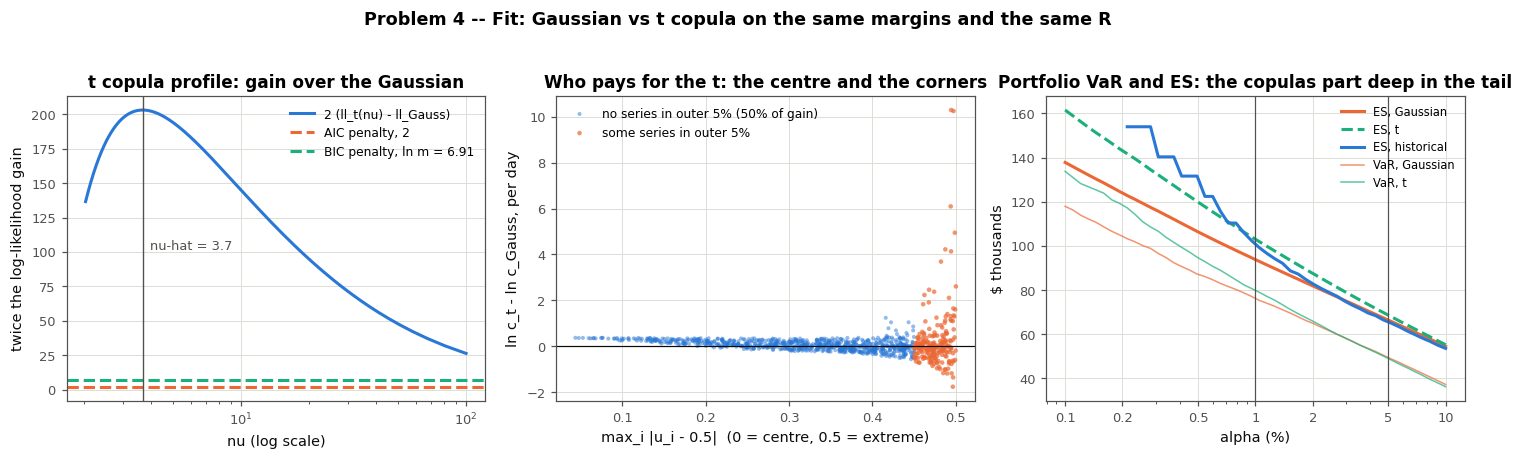

In [17]:
# (g) winner and margin; (h) which risk number moved; (i) per-day contributions
#     to ll_t - ll_Gauss; (j) tail dependence. Then the fit figure.
problem4.part_g(C4, F4)
problem4.part_h(S4)
I4 = problem4.part_i(C4)
J4 = problem4.part_j(C4)
problem4.figure_fit(C4, S4, I4)

---

# Problem 5 — Model-Based Simulation and Residual Correlation

`problem5.csv`: 501 daily prices for `MKT`, `A`, `B`, so 500 arithmetic returns.
Zero expected returns are assumed, so the simulation drops $\alpha$ and gives the
market a zero mean ($\alpha$ is still reported from the fit). Portfolios: `P1` long
\$1M `A` and long \$1M `B`; `P2` long \$1M `A` and short \$1M `B`. Model: $r_i =
\alpha_i + \beta_i r_{MKT} + \epsilon_i$, market and errors Normal.

## Predict

### (a) What the independent-errors shortcut does to each portfolio

Fact 7 (Week 02 §2.1.1) for $h_A r_A + h_B r_B$:

$$\mathrm{Var} = h_A^2\,\mathrm{Var}(r_A) + h_B^2\,\mathrm{Var}(r_B) + 2\,h_A h_B\,\mathrm{Cov}(r_A, r_B)$$

and under the model, since $\epsilon_i$ is uncorrelated with $r_{MKT}$,

$$\mathrm{Cov}(r_A, r_B) = \beta_A\beta_B\,\mathrm{Var}(r_{MKT}) + \mathrm{Cov}(\epsilon_A, \epsilon_B).$$

The shortcut sets $\mathrm{Cov}(\epsilon_A, \epsilon_B) = 0$. The variances are
untouched — each stock's own variance is $\beta_i^2\sigma_M^2 + \sigma_{\epsilon_i}^2$
either way — so the *entire* error is the one dropped cross term, $2h_Ah_B\,
\mathrm{Cov}(\epsilon_A, \epsilon_B)$. If the two stocks share an industry the market
does not capture, that covariance is positive, and:

- **`P1`** ($h_Ah_B = +1$ in (\$M)² units): a positive term is dropped, the variance is
  **understated**, the VaR is **too low**.
- **`P2`** ($h_Ah_B = -1$ in (\$M)² units): a negative term is dropped, the variance is
  **overstated**, the VaR is **too high**. The shortcut thinks the hedge does less
  than it does.

How big? Before fitting anything, the raw correlations give it away. A one-factor
model with independent errors forces $\mathrm{corr}(A,B) = \mathrm{corr}(A,M)\,
\mathrm{corr}(B,M)$. The data: $\mathrm{corr}(A,M) = 0.647$, $\mathrm{corr}(B,M) =
0.650$, so the shortcut implies $\mathrm{corr}(A,B) = 0.42$ — and the observed value
is **$0.825$**. The gap of $0.40$ is co-movement the market does not explain, so
$\mathrm{Cov}(\epsilon_A, \epsilon_B)$ is positive and large. I expect the shortcut to
miss by a lot, and **`P2` to suffer far more than `P1`**: with $\beta_A \approx
\beta_B$ the market leg of `P2` nearly cancels, so almost all of `P2`'s variance is
residual, and the dropped term is a large fraction of a small number. `P1` is
dominated by the market leg, which both versions share.

In [18]:
# Predict: the Fact 7 argument and what the raw correlations say before any fit.
D5 = problem5.prepare()
A5 = problem5.part_a(D5)


Problem 5(a) -- Predict: what the independent-errors shortcut does
  Fact 7 (Week 02 s2.1.1) for h_A r_A + h_B r_B:
    Var = h_A^2 Var(r_A) + h_B^2 Var(r_B) + 2 h_A h_B Cov(r_A, r_B)
  and under the model, Cov(r_A, r_B) = beta_A beta_B Var(r_M) + Cov(eps_A, eps_B).
  The shortcut sets Cov(eps_A, eps_B) = 0. If the stocks share an industry the
  market misses, the true Cov(eps_A, eps_B) > 0, so the shortcut drops a
  POSITIVE term from the cross-covariance:
    P1: h_A h_B = +$1M^2  -> variance UNDERSTATED -> VaR too LOW
    P2: h_A h_B = -$1M^2  -> variance OVERSTATED  -> VaR too HIGH
  Variances are untouched, so the whole error is the one cross term.

  A look at the raw correlations (no model fitted):
    corr(A, MKT) = 0.6466, corr(B, MKT) = 0.6501, corr(A, B) = 0.8251
    With independent errors a one-factor model forces corr(A, B) =
    corr(A, M) x corr(B, M) = 0.4203. The data show 0.8251: the gap of +0.405 is
    co-movement the market does not explain, so Cov(eps_A, eps_B) 

## Fit

### (b) The regressions

| stock | $\alpha$ (se) | $\beta$ (se) | residual sd ($n-1$) | residual sd ($n-2$) | $R^2$ |
|---|---|---|---|---|---|
| `A` | $+0.000205$ ($0.000578$) | $1.035$ ($0.055$) | $0.01289$ | $0.01290$ | 0.418 |
| `B` | $+0.000315$ ($0.000518$) | $0.935$ ($0.049$) | $0.01154$ | $0.01155$ | 0.423 |

Market sd $0.01055$. **Correlation between the residuals: $+0.698$.** Both alphas are
within one standard error of zero, consistent with the zero-expected-return
assumption. $R^2 \approx 0.42$ leaves 58% of each stock's variance in the residual,
and the residuals are 0.70 correlated — the shared industry the market does not
capture, in one number.

(The $n-1$ residual sd is used in the simulation so that every variance and
covariance in the problem shares one convention and the identity in part (f) is
exact; the OLS $n-2$ version differs in the third decimal.)

### (c) 100,000 simulated days, full and diagonal $\Sigma_\epsilon$

The joint vector $[r_M, \epsilon_A, \epsilon_B] \sim N(0, \mathrm{blockdiag}(\sigma_M^2,
\Sigma_\epsilon))$ (Week 05 §5.2.2) is drawn through its Cholesky root, once with the
full $\Sigma_\epsilon$ and once with its off-diagonal zeroed, from the *same* standard
normal draws; then $r_i = \beta_i r_M + \epsilon_i$.

| portfolio | $\Sigma_\epsilon$ | VaR 5% | ES 5% | closed form | MC se |
|---|---|---|---|---|---|
| `P1` | full | **\$50,298** | \$63,152 | \$50,415 | \$205 |
| `P2` | full | **\$15,841** | \$19,876 | \$15,834 | \$64 |
| `P1` | diagonal | **\$44,450** | \$55,712 | \$44,494 | \$181 |
| `P2` | diagonal | **\$28,472** | \$35,725 | \$28,507 | \$116 |

"Closed form" is $1.645\sqrt{h'\Sigma_{\text{model}}h}$ for the covariance the
simulation was drawn from; every simulated VaR is within about one Monte Carlo
standard error of it.

### (d) Delta-normal VaR straight from the sample covariance of `A` and `B`

Week 04 §4.4.1 with delta 1 for a stock, so the gradient is just the dollar
holdings: $\mathrm{VaR} = -\Phi^{-1}(0.05)\sqrt{h'\Sigma h}$.

| portfolio | sd of P&L | delta-normal VaR |
|---|---|---|
| `P1` | \$30,650 | **\$50,415** |
| `P2` | \$9,626 | **\$15,834** |

In [19]:
# (b) OLS on the market; (c) 100,000-day simulations with full and diagonal
#     residual covariance; (d) delta-normal VaR from the stocks' sample covariance.
F5 = problem5.part_b(D5)
S5 = problem5.part_c(F5)
DN5 = problem5.part_d(D5)


Problem 5(b) -- the two regressions on the market
  stock        alpha      (se)     beta     (se)   resid sd     (n-2)    R^2
  --------------------------------------------------------------------------
  A        +0.000205  0.000578   1.0353   0.0547   0.012888  0.012901  0.418
  B        +0.000315  0.000518   0.9354   0.0490   0.011538  0.011550  0.423
  --------------------------------------------------------------------------
  market sd = 0.010553   (mean +0.000764, set to 0 in the simulation)
  residual correlation corr(eps_A, eps_B) = +0.6983
  residual covariance Sigma_eps (x 1e-4):
            eps_A    eps_B
  eps_A    1.6611   1.0385
  eps_B    1.0385   1.3314
  Both alphas are within one standard error of zero, consistent with the
  zero-expected-return assumption. R^2 of ~0.42 leaves 58% of each stock's
  variance in the residual, and the residuals are 0.70 correlated: the
  shared industry the market does not capture, in one number.

Problem 5(c) -- 100,000 simulated day

## Reconcile

### (e) Did the shortcut move each portfolio as predicted?

| portfolio | full VaR | shortcut VaR | error | dropped term / true variance | shortcut variance / true |
|---|---|---|---|---|---|
| `P1` | \$50,298 | \$44,450 | **$-11.6\%$** | $+22\%$ | $0.78$ |
| `P2` | \$15,841 | \$28,472 | **$+79.7\%$** | $-224\%$ | $3.24$ |

Yes, both directions as predicted: the shortcut **understates `P1`** and **overstates
`P2`**. And `P2` is far more exposed, as predicted, for the reason predicted. Its
market leg is $(\beta_A - \beta_B)^2\sigma_M^2 = (0.100)^2\sigma_M^2$ — **1.2% of its
variance**. `P2` is essentially a bet on the residual spread $\epsilon_A -
\epsilon_B$, and the residual correlation of $0.70$ is what makes that spread narrow:
$\mathrm{Var}(\epsilon_A - \epsilon_B) = \sigma_A^2 + \sigma_B^2 - 2\rho\sigma_A\sigma_B$,
and the last term removes two-thirds of the first two. Drop it and the model thinks
the hedge does nothing; the variance more than triples and the VaR is 80% too high.
For `P1` the dropped term is 22% of a variance dominated by the shared market leg,
so the VaR is 12% too low — wrong in the dangerous direction, but by a smaller
fraction.

The general statement: the shortcut's error is a fixed quantity, $2h_Ah_B\,
\mathrm{Cov}(\epsilon_A, \epsilon_B)$, and it matters in proportion to how small the
rest of the portfolio's variance is. Hedged, market-neutral and long–short books are
exactly the portfolios whose remaining variance is small, so they are exactly the
portfolios the shortcut ruins. Week 05 §5.2.2 calls $\Sigma_\epsilon$ "the part that is
easy to forget"; `P2` is what forgetting it costs.

### (f) The full-residual simulation against the delta-normal number

| portfolio | MC, full $\Sigma_\epsilon$ | closed form | delta normal |
|---|---|---|---|
| `P1` | \$50,298 | \$50,415 | \$50,415 |
| `P2` | \$15,841 | \$15,834 | \$15,834 |

They agree to within Monte Carlo noise (\$205 and \$64 standard errors), and the
closed-form version of the simulation agrees with the delta-normal number to the
dollar — because

$$\max\left|\,\beta\beta'\sigma_M^2 + \Sigma_\epsilon - \Sigma_{\text{sample}}\,\right| = 1.6\times10^{-19}.$$

**The model covariance is the sample covariance**, to machine precision. OLS makes
each residual orthogonal to the regressor in sample, so Fact 7 splits
$\mathrm{Cov}(r_A, r_B)$ *exactly* into $\beta_A\beta_B\mathrm{Var}(r_M) +
\mathrm{Cov}(\epsilon_A, \epsilon_B)$ when every piece is estimated on the same rows
with the same divisor. Week 05 §5.2.1 says why this had to happen: with everything
Normal, "OLS is the same thing as just using a joint, multivariate distribution on
$Y$ and $X$" — $\Sigma_{YX}\Sigma_{XX}^{-1}$ *is* $\beta$ and the conditional
covariance *is* the residual covariance, so the regression was already inside the
joint Normal. Fitting it, simulating its pieces and recombining them returns the
joint Normal we could have written down at the start, and the delta-normal VaR is
that joint Normal's 5% quantile. The simulation is "a check on the machinery rather
than a result to use."

**When they stop agreeing** — whenever one of the conditions that made the
equivalence hold is removed:

- **A non-Normal piece.** $t$-distributed errors, or a $t$ market: the sum is no
  longer Normal, $1.645\sigma$ is no longer its 5% quantile, and the delta-normal
  number is wrong while the simulation is right. This is the case Week 05 §5.7
  builds, and the reason the copula exists — "it stops being true the moment any
  piece is not normal."
- **A non-linear position.** Options on `A` and `B`: delta normal linearises and
  misses gamma; the simulation reprices.
- **Pieces estimated on different footings.** An EW market variance with
  equal-weight residuals, regressions on different windows, a $\beta$ taken from
  outside the sample: the in-sample identity $\Sigma_{\text{model}} = \Sigma_{\text{sample}}$
  no longer holds and the two numbers describe different covariances.
- **The shortcut itself.** A diagonal $\Sigma_\epsilon$ is a model covariance that is
  *not* the sample covariance, which is the whole of this problem.
- **Means that matter.** At a one-day horizon dropping $\alpha$ is harmless; at a
  one-year horizon it is not, and the absolute and relative VaR conventions of Week
  04 §4.2.1 separate.


Problem 5(e) -- did the shortcut move each portfolio as predicted?
  portfolio                 full VaR  diag VaR  VaR error  dropped/var  var ratio
  -------------------------------------------------------------------------------
  P1 (long A, long B)        $50,298   $44,450     -11.6%       +22.1%      0.779
  P2 (long A, short B)       $15,841   $28,472     +79.7%      -224.1%      3.241
  -------------------------------------------------------------------------------
  'dropped/var' is the term the shortcut drops, 2 h_A h_B Cov(eps_A, eps_B), as
  a fraction of the portfolio's true variance; 'var ratio' is the shortcut's
  variance over the true one. P1: UNDERSTATED, as predicted. P2: OVERSTATED,
  as predicted. P2 is far more exposed: its
  market leg is (beta_A - beta_B)^2 sigma_M^2 = (+0.0999)^2 sigma_M^2, only 1.2% of its
  variance, so P2 is essentially a bet on the residual spread -- and the
  residual correlation of 0.70 is what makes that spread narrow. Drop
  it and the 

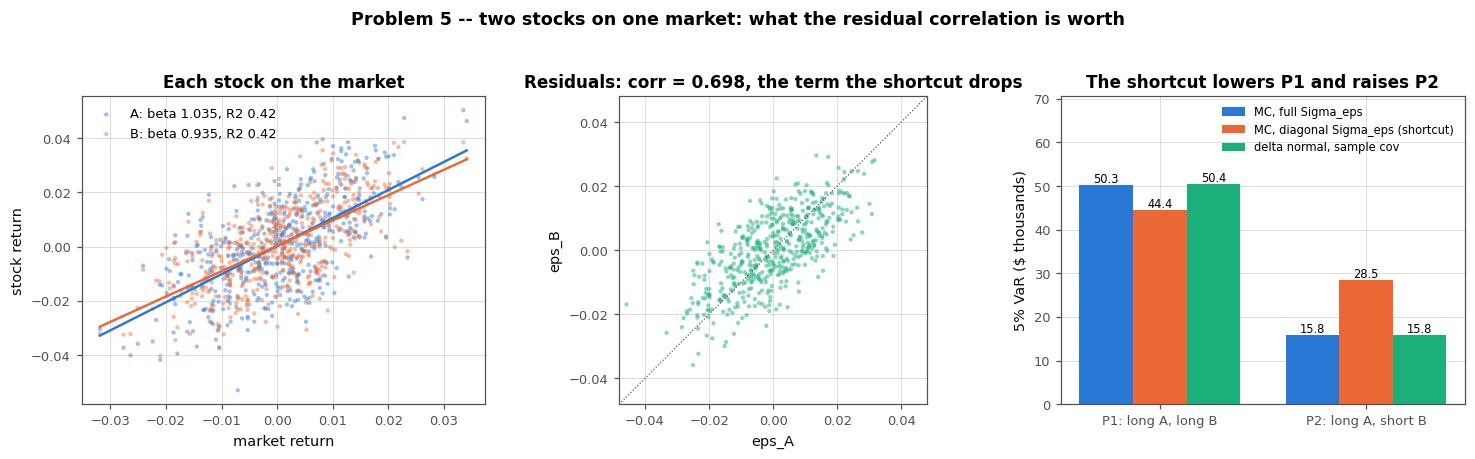

In [20]:
# (e) direction and size of the shortcut's error; (f) the simulation against the
#     delta-normal number and the exact OLS identity. Then the figure.
problem5.part_e(F5, S5)
problem5.part_f(D5, F5, S5, DN5)
problem5.figure(D5, F5, S5, DN5)

---

# Summary

| problem | prediction | fit | matched? |
|---|---|---|---|
| **1** | Pairwise non-PSD, complete-case PSD but barely ($\lambda_{\min} \le 0.0014$); `D` pairs least reliable; the tracking portfolio is the exposed direction | $\lambda_{\min}$: $-0.0111$ pairwise, $+0.0015$ complete; tracking variance $-1.8\times10^{-6}$; Higham and R–J repair it to $+0.68\times10^{-6}$ | **Yes** on PSD and on the direction. Higham moved the *best*-estimated entries most — it reads the eigenvector, not the sample sizes |
| **2** | 4 ≤ 1 < 5 < 2 < 3; EW weights 70% / 91% on a 39-day regime; kurtosis a regime artefact | \$18.9k < \$19.6k < \$20.6k < \$34.6k < \$38.7k; within-regime excess kurtosis $-0.05$ and $-0.20$; mixture implies $+2.7$ vs $+2.2$ observed | **Yes**, including the $t$ landing lowest. The EW gap (\$4.1k) is inside one standard error |
| **3** | Diversified VaR larger (profit → ≈ \$450k loss), ES about half; Normal VaR describes an empty region | VaR −\$169k vs +\$415k; ES \$887k vs \$542k; VaR not subadditive at 5%, ES is; flips at 1% | **Yes**. Count-based ES was 12% low on the diversified side (low-recovery defaults fill the tail) |
| **4** | `X1` Normal, `X2`/`X3` $t$; corners 3.4 Poisson sd above Gaussian; $t$ copula wins with $\nu \approx 4$ | margins as predicted; $\hat\nu = 3.66$, $\Delta\text{BIC} = +196$; corners 48 data / 31 Gaussian / 52 $t$; 1% ES moves 10%, 5% VaR $-1\%$ | **Yes**. Surprise: half the likelihood gain is from the centre and most of the rest from *discordant* extremes, not joint crashes |
| **5** | Shortcut understates `P1`, overstates `P2`; `P2` far more exposed; raw correlations imply a large residual covariance | residual corr $0.70$; `P1` $-11.6\%$, `P2` $+79.7\%$; full simulation = delta normal to $10^{-19}$ in $\Sigma$ | **Yes** on all three |

## What did not go as expected, and what it taught

Every directional prediction held, so the lessons are in the places where the
*mechanism* turned out to be different from the one I had in mind.

**Problem 1(h).** I expected a repair to concentrate its changes on the entries I
had flagged as unreliable. It did the reverse, and the reason is simple once stated:
an unweighted Higham minimises a Frobenius distance in which every entry is equally
cheap, so it removes the negative eigen-component wherever that component lives —
in the `IDX` row, the best-estimated entries in the matrix. The repair solves a
geometry problem, not a statistics problem. If the statistics are to enter, they
have to be put in explicitly through the weight matrix $W$.

**Problem 2(f).** The fitted $t$ was the best-fitting distribution by likelihood and
the worst VaR estimate for the purpose, and I had under-appreciated how completely a
regime switch can manufacture kurtosis: two Normals with no fat tails at all produce
*more* excess kurtosis than the sample shows. "Fat tails" in a pooled sample is a
statement about the sample's history, not about any one day's distribution.

**Problem 4(i).** I had assumed the evidence for a $t$ copula would come from the
joint tail days. Half of it came from the 793 days on which nothing extreme happened
to any asset, and nearly all of the rest from days when the assets moved extremely
in *opposite* directions — the concordant extremes, including the headline day 951,
scored about evenly under both copulas. The information criterion scores the whole
density; the thing a risk manager buys a $t$ copula for is one corner of it. Here
the corner counts confirmed the criterion's verdict directly, and on data where they
did not, I would trust the counts.

**Problem 3** and **Problem 5** were cases where Week 04 §4.3.2 and Week 05 §5.2 said
in advance exactly what would happen, and the main value of running them was to see
the size: a 3.8-point move in probability mass across the 5% line turning a profit
into a \$415k VaR, and a residual correlation of 0.70 turning a \$16k hedge VaR into
a \$28k one when it is forgotten.